In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
h2 = ['gdp', 'inflation_df', 'agr_land', 'livestock_prod']

### Import the data
* Import data that describe countries in one point

In [3]:
countries_win = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [4]:
countries_win.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


### Delete statistic from list of macros

In [5]:
list(countries_win.columns)

['Country',
 'labor_force_mean',
 'labor_force_median',
 'labor_force_std',
 'labor_force_min',
 'labor_force_max',
 'labor_force_last',
 'livestock_prod_mean',
 'livestock_prod_median',
 'livestock_prod_std',
 'livestock_prod_cv',
 'livestock_prod_min',
 'livestock_prod_max',
 'livestock_prod_last',
 'urban_pop_mean',
 'urban_pop_median',
 'urban_pop_min',
 'urban_pop_max',
 'urban_pop_last',
 'gov_exp_mean',
 'gov_exp_median',
 'gov_exp_std',
 'gov_exp_cv',
 'gov_exp_min',
 'gov_exp_max',
 'gov_exp_last',
 'gov_exp_growth',
 'gov_exp_trend',
 'reserves_mean',
 'reserves_median',
 'reserves_std',
 'reserves_cv',
 'reserves_min',
 'reserves_max',
 'reserves_last',
 'investment_mean',
 'investment_median',
 'investment_std',
 'investment_cv',
 'investment_min',
 'investment_max',
 'investment_last',
 'investment_growth',
 'investment_trend',
 'cpi_mean',
 'cpi_median',
 'cpi_std',
 'cpi_cv',
 'cpi_min',
 'cpi_max',
 'cpi_last',
 'gdp_mean',
 'gdp_median',
 'gdp_std',
 'gdp_cv',
 'gdp_mi

In [6]:
def filter_macro_columns_with_country(df, macro_keywords, keep_column="Country"):
    """
    Conserva solo las columnas del DataFrame que contienen alguna palabra clave en 'macro_keywords',
    además de la columna 'Country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original con muchas columnas macroeconómicas.
    - macro_keywords: list of str
        Lista de palabras clave que deben estar presentes en el nombre de las columnas a conservar.
    - keep_column: str
        Columna adicional que se desea conservar (por defecto 'Country').

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con solo las columnas relevantes.
    """

    columnas_filtradas = [
        col for col in df.columns
        if any(keyword in col for keyword in macro_keywords)
    ]

    # Asegurar que 'Country' esté incluido si existe en el DataFrame
    if keep_column in df.columns and keep_column not in columnas_filtradas:
        columnas_filtradas.insert(0, keep_column)

    df_filtrado = df[columnas_filtradas].copy()

    print(f"Columnas conservadas ({len(columnas_filtradas)}): {columnas_filtradas}")
    return df_filtrado

In [7]:
countries_win_h2 = filter_macro_columns_with_country(countries_win, h2)

Columnas conservadas (34): ['Country', 'livestock_prod_mean', 'livestock_prod_median', 'livestock_prod_std', 'livestock_prod_cv', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_last', 'gdp_mean', 'gdp_median', 'gdp_std', 'gdp_cv', 'gdp_min', 'gdp_max', 'gdp_last', 'gdp_growth', 'gdp_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'gdp_skew', 'gdp_kurtosis']


In [8]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from a DataFrame where the value in the specified column matches any country in the given list.

    Parameters:
    - df (pd.DataFrame): The original DataFrame.
    - country_list (list): A list of country names to be removed from the DataFrame.
    - column (str): The name of the column containing country identifiers (default is "Country").

    Returns:
    - pd.DataFrame: A new DataFrame excluding rows where the country is in the provided list.
    """
    return df[~df[column].isin(country_list)].copy()

In [9]:
countries_to_remove = ["Hong-Kong","India","Turkey", "Iceland", "Russia"]

In [10]:
countries_win_h2 = remove_rows_by_countries(countries_win_h2, countries_to_remove)

### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [12]:
from sklearn.cluster import KMeans

In [13]:
from sklearn.metrics import silhouette_samples

In [14]:
from matplotlib import cm

In [15]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [16]:
import country_converter as coco

In [17]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

#### cluster_input_h2

In [18]:
cluster_input_h2 = countries_win_h2.select_dtypes(include='number')
cluster_input_h2.head()

,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,gdp_std,...,agr_land_cv,agr_land_min,agr_land_max,agr_land_last,agr_land_growth,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis
0,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,4.529963,...,0.364734,0.447020,0.562871,0.566279,0.433187,-0.755144,0.299427,0.588591,-0.393881,-0.533219
1,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,2.538337,...,-0.055775,-0.282775,-0.282528,-0.312030,-0.547518,0.833938,0.008353,-0.419006,-0.097436,-0.278300
2,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,2.878367,...,-0.539514,0.402875,0.367441,0.416555,0.181257,-0.755144,0.405169,0.417570,0.111506,-0.422868
3,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,6.189334,...,0.456347,-0.551558,-0.535051,-0.579753,-0.547518,0.061606,-0.670852,-0.592022,-0.013102,-0.531518
4,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,2.336594,...,-0.706821,0.538105,0.461314,0.510619,0.293228,0.674399,-0.264767,0.329780,0.304080,-0.121597


In [19]:
countries_win_h2.head()

,Country,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,...,agr_land_cv,agr_land_min,agr_land_max,agr_land_last,agr_land_growth,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis
0,Australia,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,...,0.364734,0.447020,0.562871,0.566279,0.433187,-0.755144,0.299427,0.588591,-0.393881,-0.533219
1,Austria,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,...,-0.055775,-0.282775,-0.282528,-0.312030,-0.547518,0.833938,0.008353,-0.419006,-0.097436,-0.278300
2,Belgium,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,...,-0.539514,0.402875,0.367441,0.416555,0.181257,-0.755144,0.405169,0.417570,0.111506,-0.422868
3,Brazil,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,...,0.456347,-0.551558,-0.535051,-0.579753,-0.547518,0.061606,-0.670852,-0.592022,-0.013102,-0.531518
4,Bulgaria,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,...,-0.706821,0.538105,0.461314,0.510619,0.293228,0.674399,-0.264767,0.329780,0.304080,-0.121597


#### Using the elbow method to find the optimal number of clusters

In [20]:
distortions = []

In [21]:
import time

In [22]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


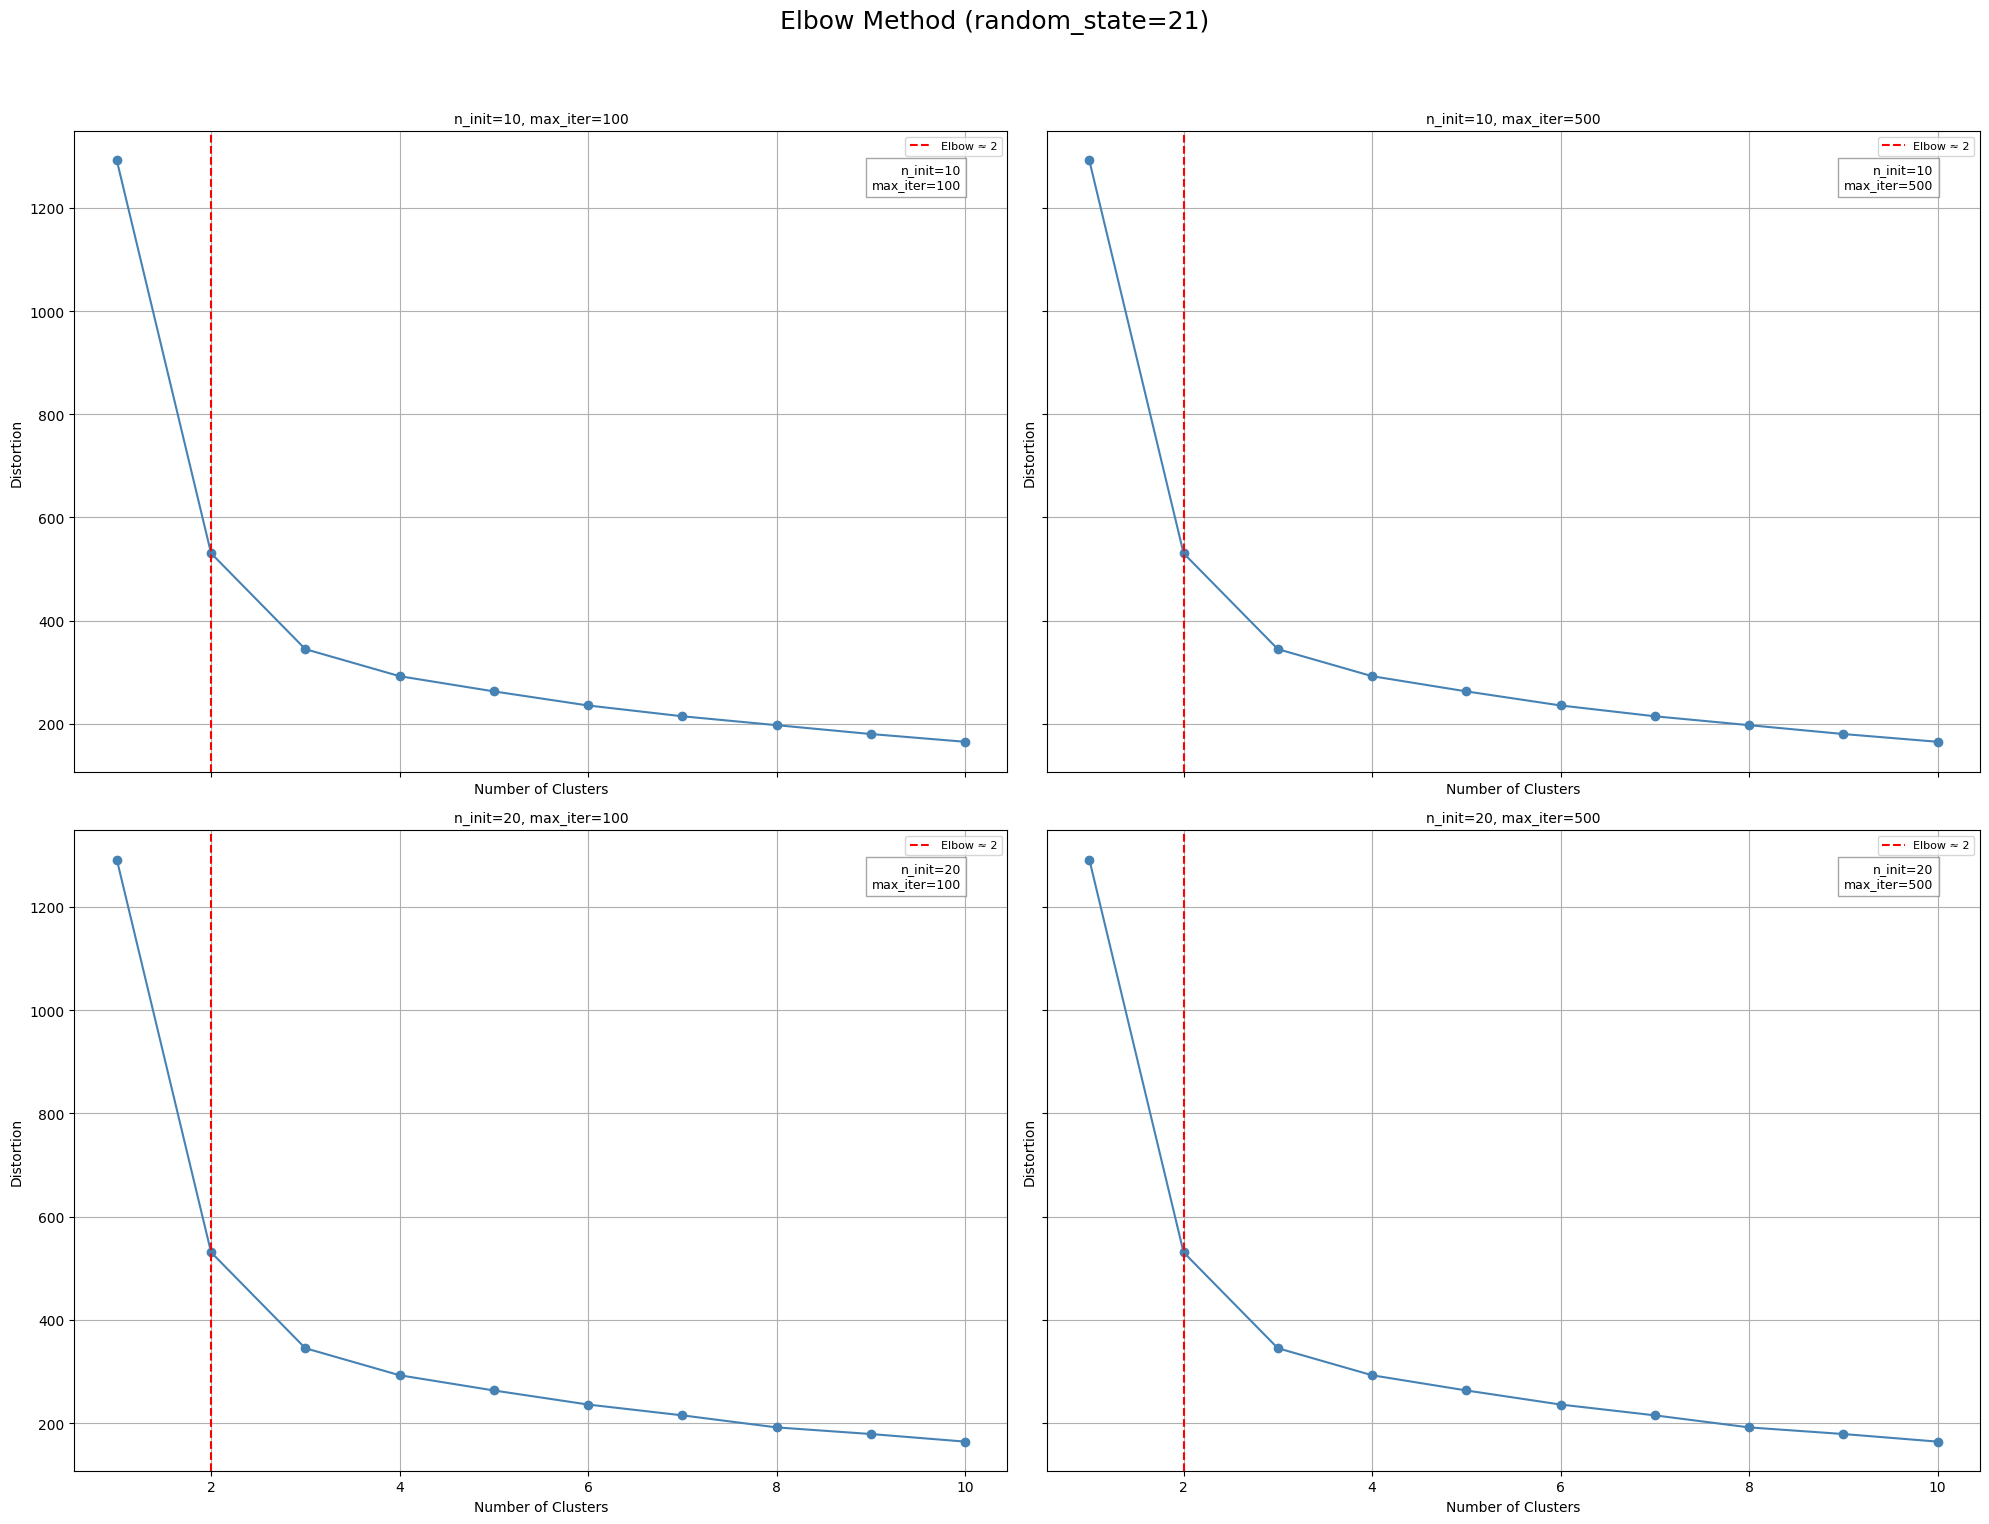


Running elbow plots for random_state=42


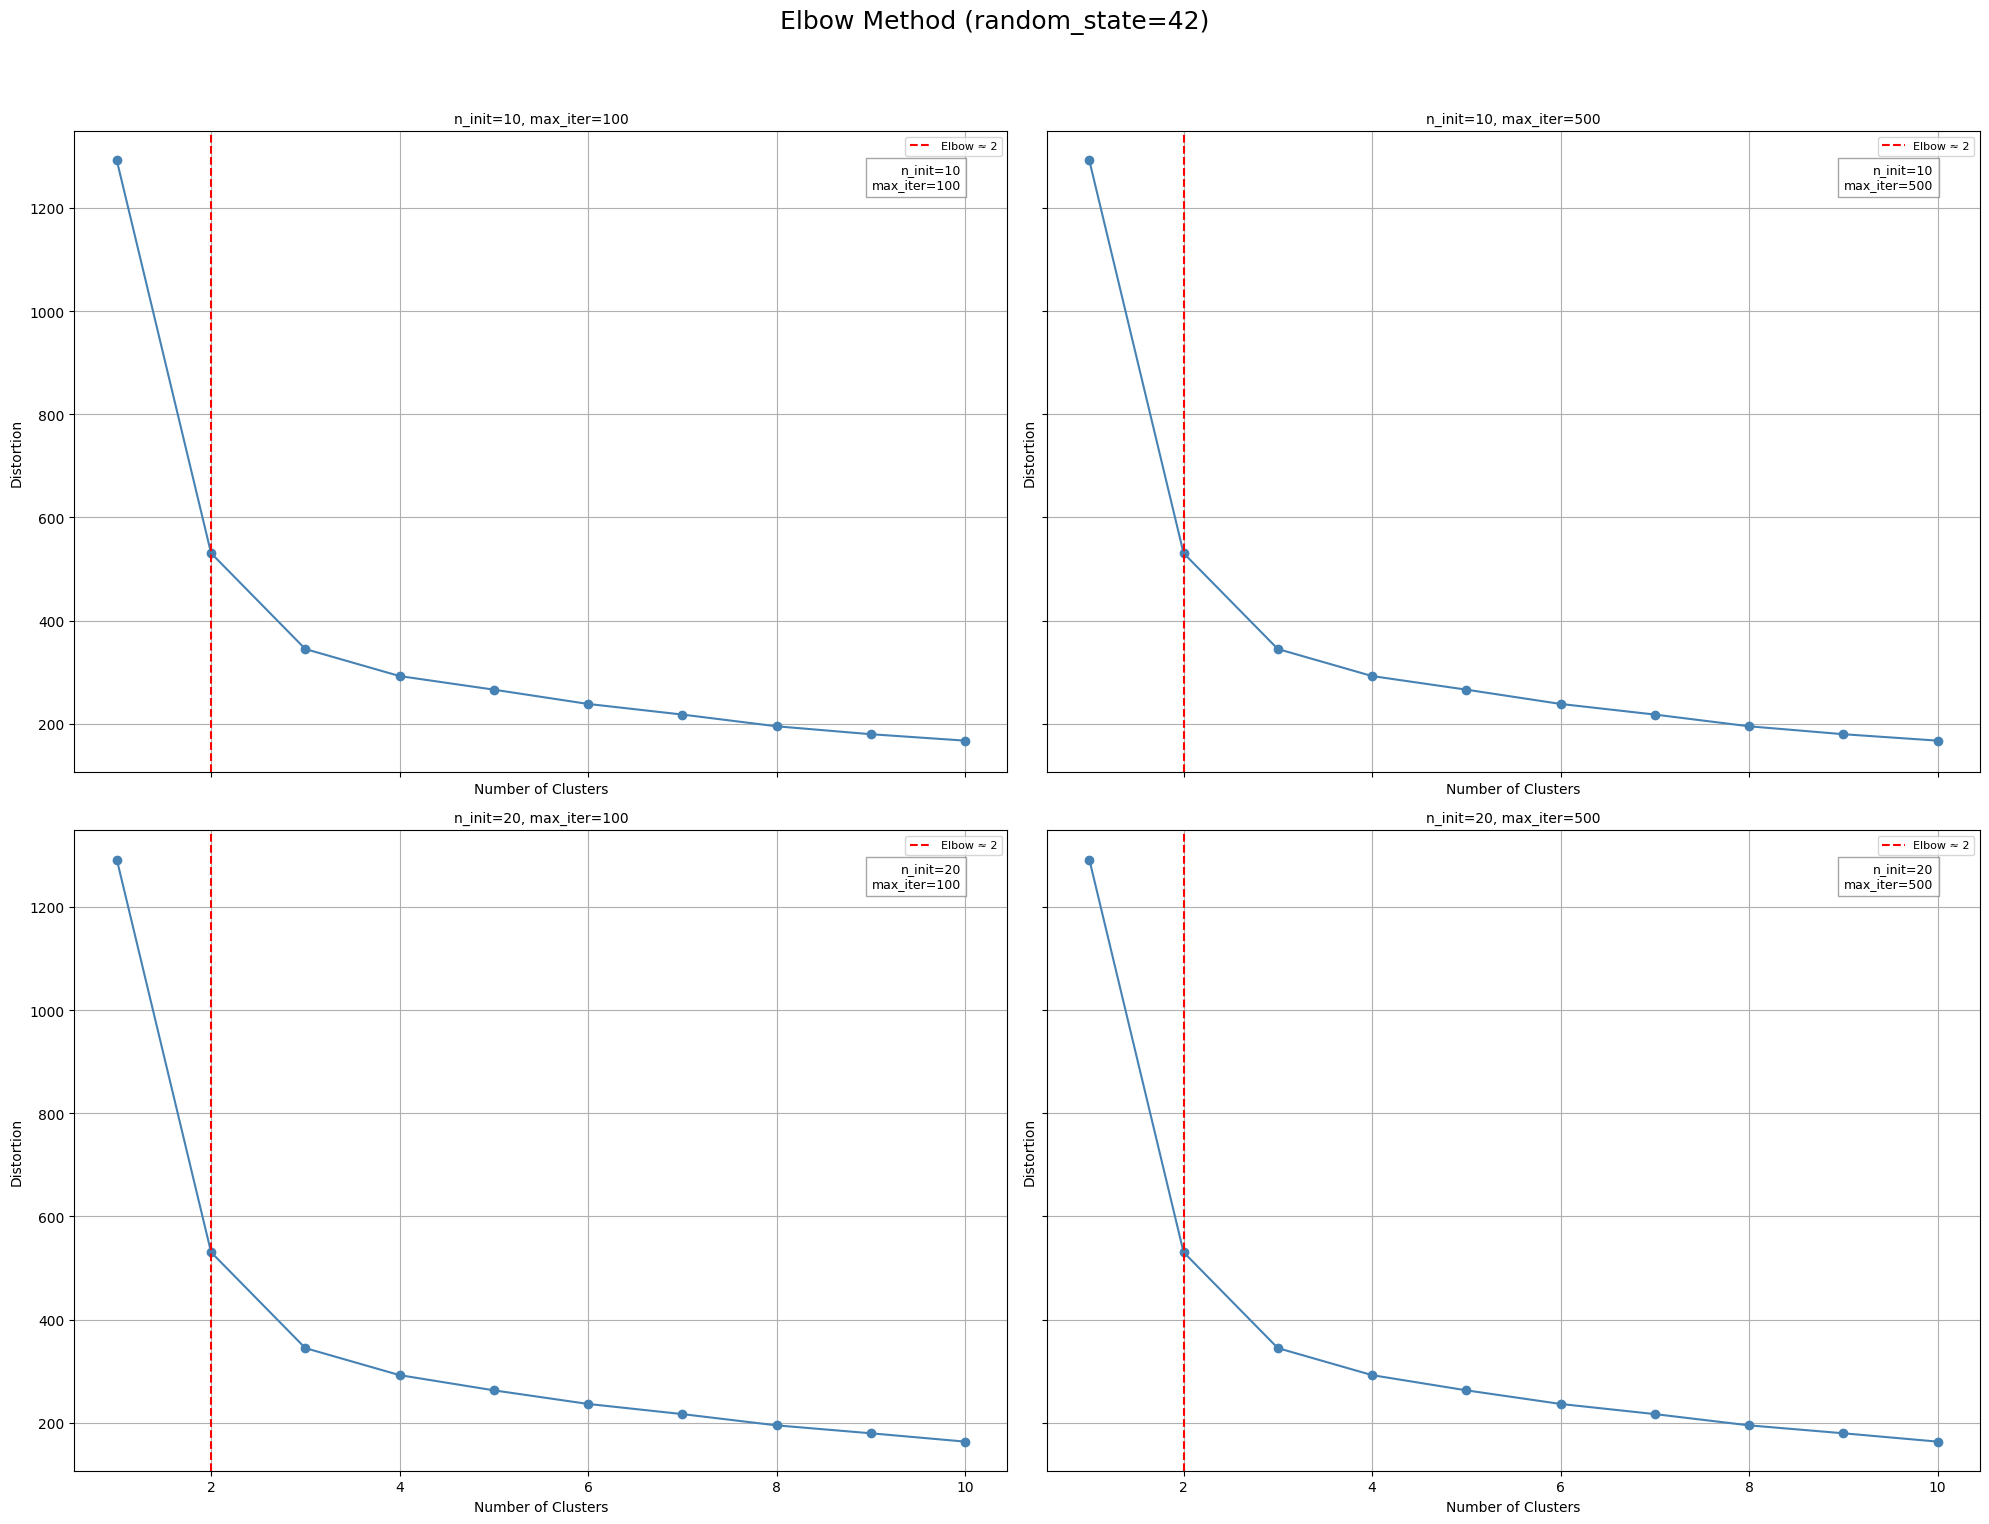


Total execution time: 8.69 seconds


In [23]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input_h2)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [24]:
km_c2_ni20_maxi500_h2 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [25]:
ym_c2_ni20_maxi500_h2 = km_c2_ni20_maxi500_h2.fit(cluster_input_h2)

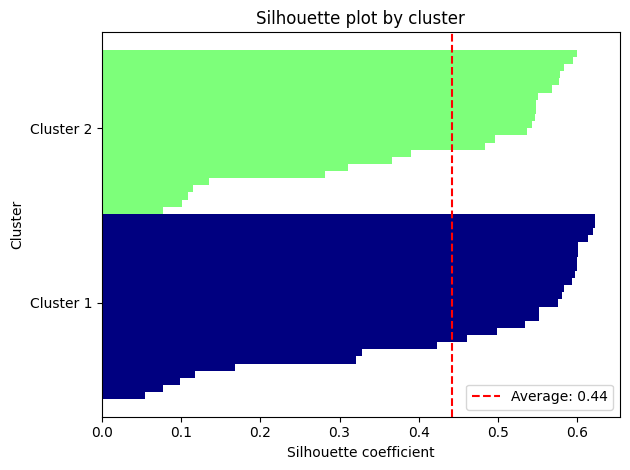

In [26]:
silhoutte_c2_ni20_maxi500_h2 = plot_silhouette(ym_c2_ni20_maxi500_h2, cluster_input_h2)

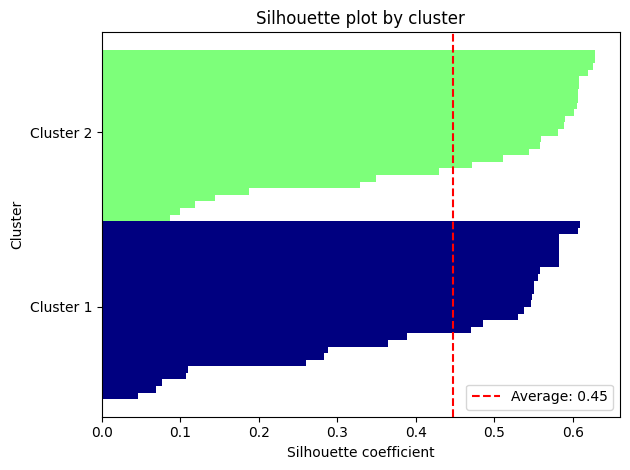

In [63]:
silhoutte_c2_ni20_maxi500_h2 = plot_silhouette(ym_c2_ni20_maxi500_h2, cluster_input_h2)

In [27]:
np.bincount(ym_c2_ni20_maxi500_h2.labels_)

array([26, 23])

In [28]:
c2_ni20_maxi500_h2 = countries_win_h2.copy()

In [29]:
c2_ni20_maxi500_h2['cluster'] = ym_c2_ni20_maxi500_h2.labels_

In [30]:
c2_ni20_maxi500_h2['ISO_A3'] = coco.convert(names=c2_ni20_maxi500_h2['Country'], to='ISO3')

In [31]:
clusters_c2_ni20_maxi500_h2 = c2_ni20_maxi500_h2[['Country', 'ISO_A3', 'cluster']].copy()

In [32]:
clusters_c2_ni20_maxi500_h2.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500_h2['Country'], to='continent'
)

In [33]:
print_cluster_groups(clusters_c2_ni20_maxi500_h2)


🌍 Cluster 0 (26 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malaysia (Asia)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - Spain (Europe)
 - Switzerland (Europe)

🌍 Cluster 1 (23 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Japan (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Sweden (Europe)
 - Thailand (

In [34]:
clusters_c2_ni20_maxi500_h2['Country'] = clusters_c2_ni20_maxi500_h2['Country'].replace('Czech','Czech Republic')

In [35]:
clusters_c2_ni20_maxi500_h2.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h2_without4_countries.parquet')

#### c3_ni20_maxi500_h2

In [36]:
km_c3_ni20_maxi500_h2 = KMeans(n_clusters=3,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [37]:
ym_c3_ni20_maxi500_h2 = km_c3_ni20_maxi500_h2.fit(cluster_input_h2)

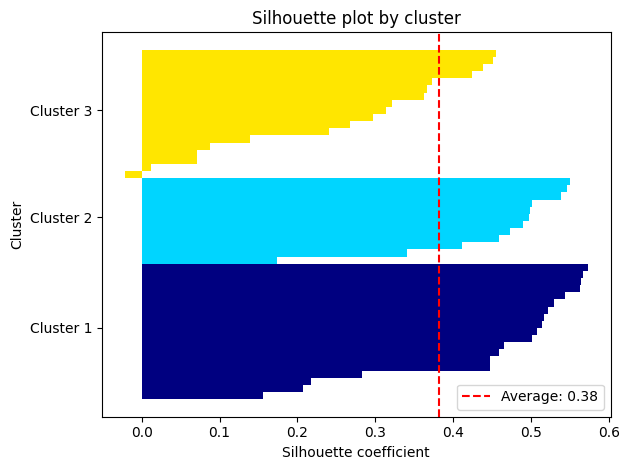

In [38]:
silhoutte_c3_ni20_maxi500_h2 = plot_silhouette(ym_c3_ni20_maxi500_h2, cluster_input_h2)

In [39]:
# Calculate silhouette scores for each sample
silhouette_vals = silhouette_samples(cluster_input_h2, ym_c3_ni20_maxi500_h2.labels_)

# Add silhouette scores to the DataFrame
c2_ni20_maxi500_h2['silhouette_score'] = silhouette_vals

# Filter rows with negative silhouette scores
negative_silhouette = c2_ni20_maxi500_h2[c2_ni20_maxi500_h2['silhouette_score'] < 0]

# Display or inspect the rows with negative silhouette scores
print(negative_silhouette)

   Country  livestock_prod_mean  livestock_prod_median  livestock_prod_std  \
34    Peru              4.70944               4.731362            2.047482   

    livestock_prod_cv  livestock_prod_min  livestock_prod_max  \
34           0.057789            4.598146            4.761319   

    livestock_prod_last  gdp_mean  gdp_median  ...  agr_land_last  \
34             4.761319  5.324274    5.250721  ...      -1.003879   

    agr_land_growth  agr_land_skew  agr_land_kurtosis  agr_land_trend  \
34         0.306021       0.833938           0.405169        0.466881   

    gdp_skew  gdp_kurtosis  cluster  ISO_A3  silhouette_score  
34 -0.253948     -0.180131        0     PER         -0.021627  

[1 rows x 37 columns]


### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [40]:
clusters_c2_ni20_maxi500_h2.shape

(49, 4)

In [47]:
df_hpi = pd.read_parquet('../data/clean_hpi.parquet')

In [48]:
df_hpi.shape

(15, 58)

In [45]:
def remove_columns_by_list(df, column_list):
    """
    Removes columns from a DataFrame whose names are included in the provided list.
    Also returns a list of column names from the input list that were not found in the DataFrame.

    Parameters:
    - df (pd.DataFrame): The original DataFrame.
    - column_list (list): A list of column names to be removed.

    Returns:
    - filtered_df (pd.DataFrame): A new DataFrame without the specified columns.
    - missing_columns (list): A list of column names from 'column_list' that were not found in the DataFrame.
    """
    existing_columns = set(df.columns)
    missing_columns = [col for col in column_list if col not in existing_columns]
    columns_to_remove = [col for col in column_list if col in existing_columns]
    filtered_df = df.drop(columns=columns_to_remove).copy()
    return filtered_df, missing_columns

In [49]:
df_hpi, missing_columns = remove_columns_by_list(df_hpi, countries_to_remove)

In [50]:
missing_columns

[]

In [51]:
df_hpi.shape

(15, 53)

In [52]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [53]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi, clusters_c2_ni20_maxi500_h2)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Czech-Republic
 - Indonesia
 - Macedonia
 - Morocco
 - New-Zealand
 - South-Africa
 - South-Korea
 - United-Kingdom
 - Year


In [54]:
countries_to_remove2 = ['Indonesia', 'China', 'Macedonia', 'Morocco']

In [55]:
df_hpi, missing_columns = remove_columns_by_list(df_hpi, countries_to_remove2)

In [64]:
def replace_country_names(df):
    """
    Replaces specific values in the 'Country' column based on their appearance order.
    Handles repeated ambiguous entries like 'South' by assigning distinct names based on position.

    Parameters:
    - df (pd.DataFrame): The original DataFrame containing a 'Country' column.

    Returns:
    - pd.DataFrame: A new DataFrame with updated country names.
    """
    df = df.copy()

    # Dictionary of direct replacements
    replacements = {
        "Czech Republic": "Czech-Republic",
        "New Zealand": "New-Zealand",
        "United Kingdom": "United-Kingdom"
    }

    # List of replacements for ambiguous 'South' entries
    south_replacements = ["South-Africa", "South-Korea"]
    south_index = 0

    def clean_name(name):
        nonlocal south_index
        name = name.strip()
        if "South" in name:
            if south_index < len(south_replacements):
                new_name = south_replacements[south_index]
                south_index += 1
                return new_name
            else:
                return name  # fallback if more than two "South" entries
        return replacements.get(name, name)

    df["Country"] = df["Country"].astype(str).apply(clean_name)
    return df

In [65]:
clusters_c2_ni20_maxi500_h2 = replace_country_names(clusters_c2_ni20_maxi500_h2)

In [67]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi, clusters_c2_ni20_maxi500_h2)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


In [68]:
clusters_c2_ni20_maxi500_h2.shape

(49, 4)

In [69]:
df_hpi.shape

(15, 49)

### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [70]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

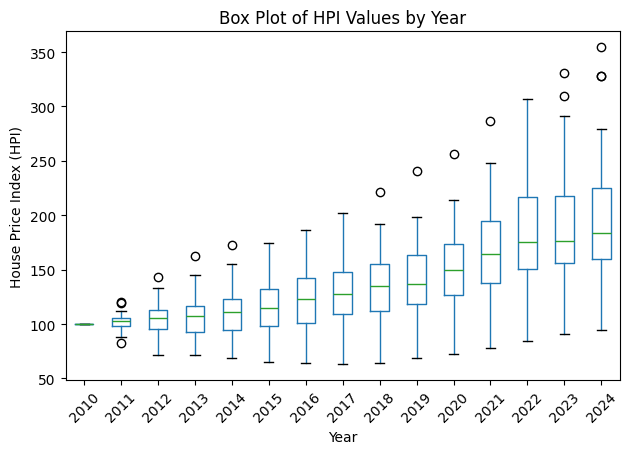

In [71]:
plot_hpi_boxplots_by_year(df_hpi)

In [72]:
from scipy.stats.mstats import winsorize

In [76]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [77]:
df_hpi_win1 = round_and_winsorize_hpi(df_hpi)

<Figure size 1400x600 with 0 Axes>

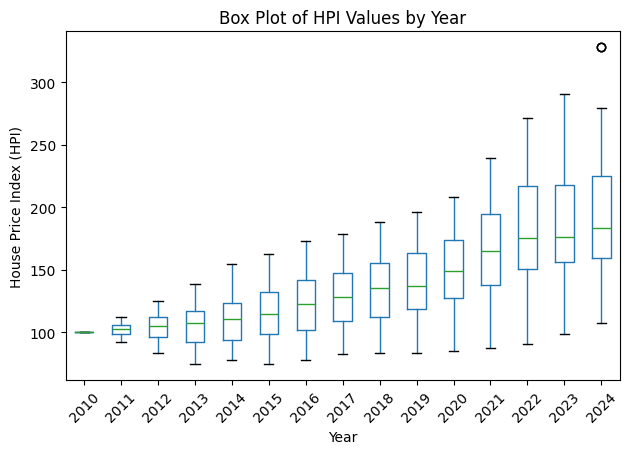

In [78]:
plot_hpi_boxplots_by_year(df_hpi_win1)

In [83]:
df_hpi_win2 = round_and_winsorize_hpi(df_hpi_win1, limits=(0.07, 0.07))

<Figure size 1400x600 with 0 Axes>

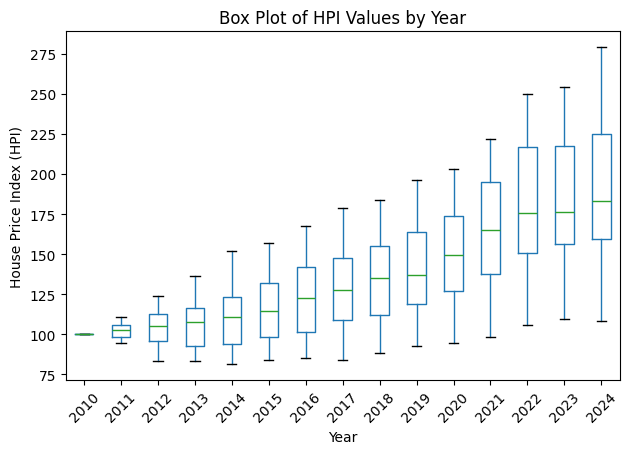

In [84]:
plot_hpi_boxplots_by_year(df_hpi_win2)

In [85]:
df_hpi_win2.to_parquet("../data/hpi_4countries_deleted_2win_005_007.parquet")

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [86]:
import random

In [87]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

### Sampling experiment with seed 32

🔍 Cluster 0 selected. Excluding country: Bulgaria
📊 Sampling from countries: ['Austria', 'Belgium', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New-Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


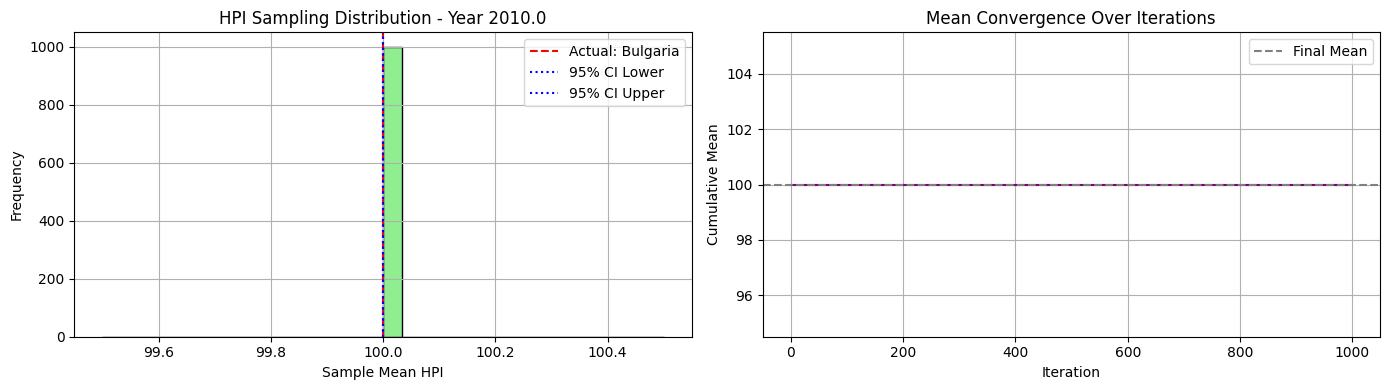


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58 100.16  96.68 108.47 103.17  94.53  94.49 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


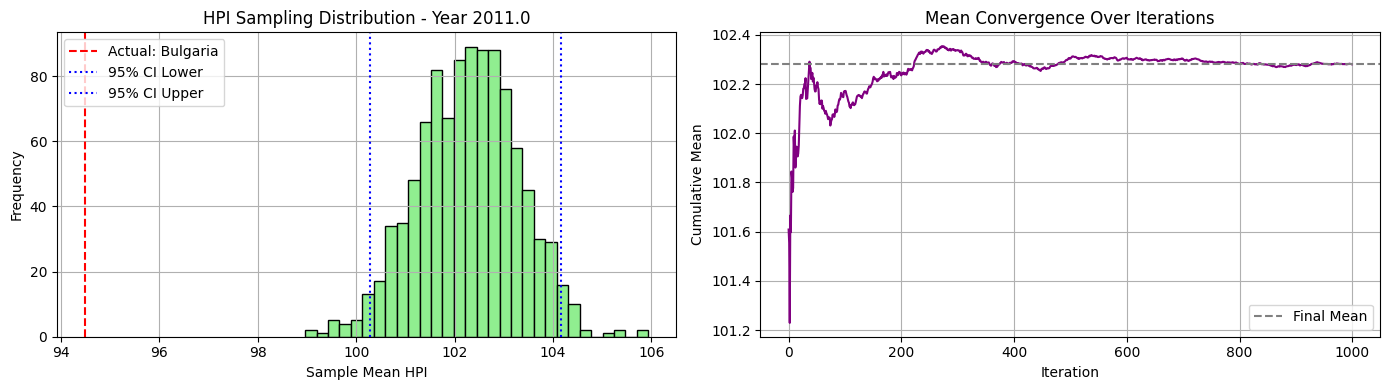


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  98.62  91.54 116.34 105.64  83.51  83.51 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  83.51
 112.02  95.73  95.63  83.51 113.72]


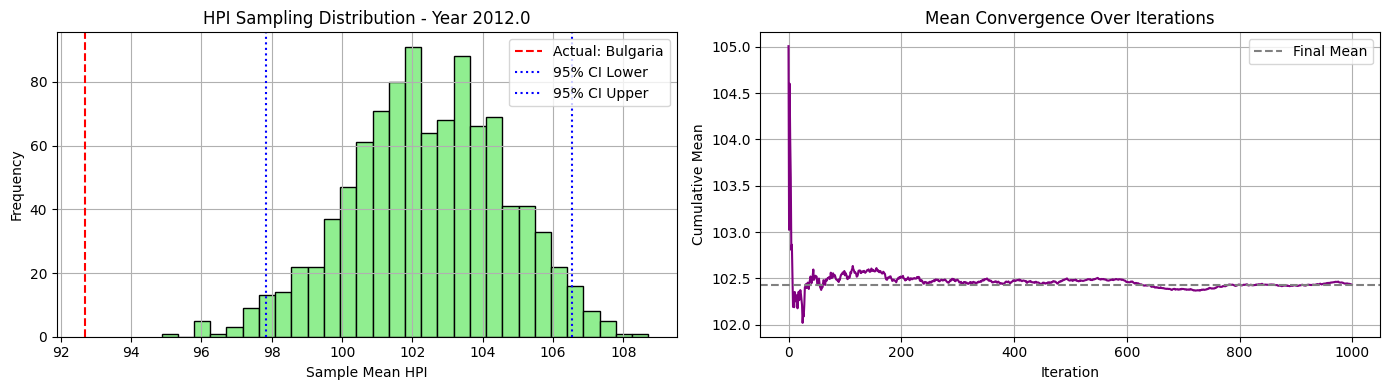


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  94.7   85.58 128.77 106.87  83.06  83.06 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   83.06
 115.56  96.53  90.62  83.06 118.3 ]


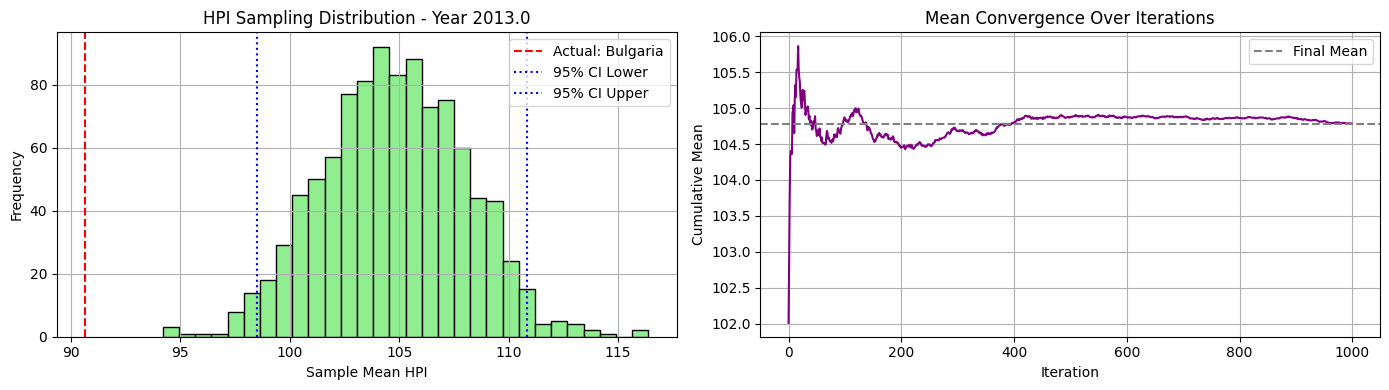


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  93.19  81.38 146.41 106.5   81.38  84.66 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  81.38
 112.25  97.8   84.64  81.38 121.46]


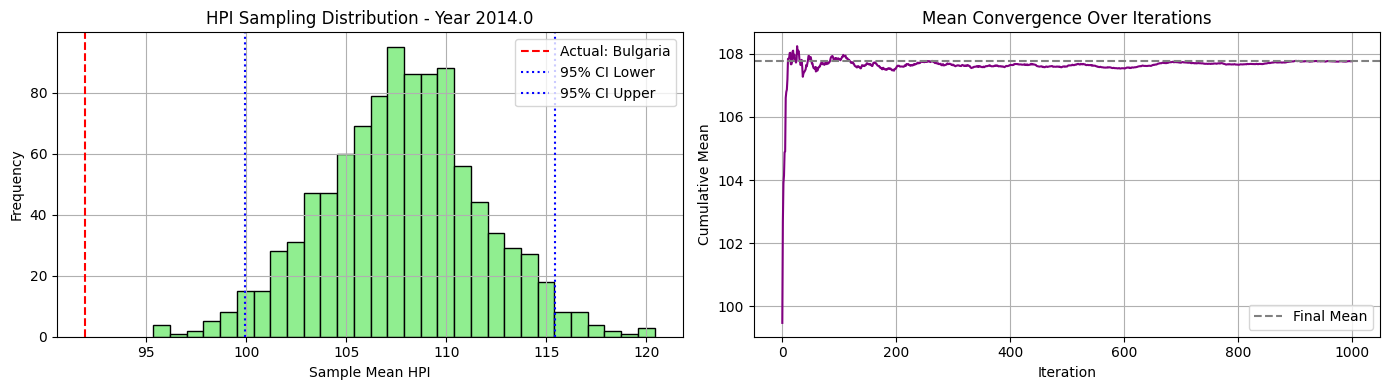


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  90.54  83.68 156.46 106.5   83.68  94.36 140.12  84.67
 124.46 118.76 124.78 157.04 109.83  89.69 137.18 157.04  93.15  83.68
 107.92 103.    85.32  83.68 124.08]


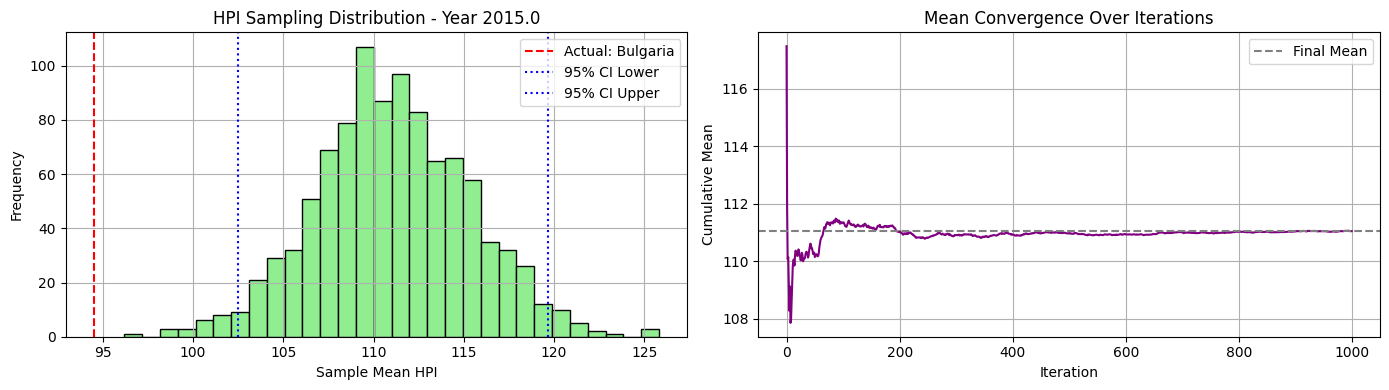


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72  91.33  84.88 163.86 107.86  84.88 101.42 150.56  84.88
 135.02 125.16 132.28 167.48 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   84.88 124.32]


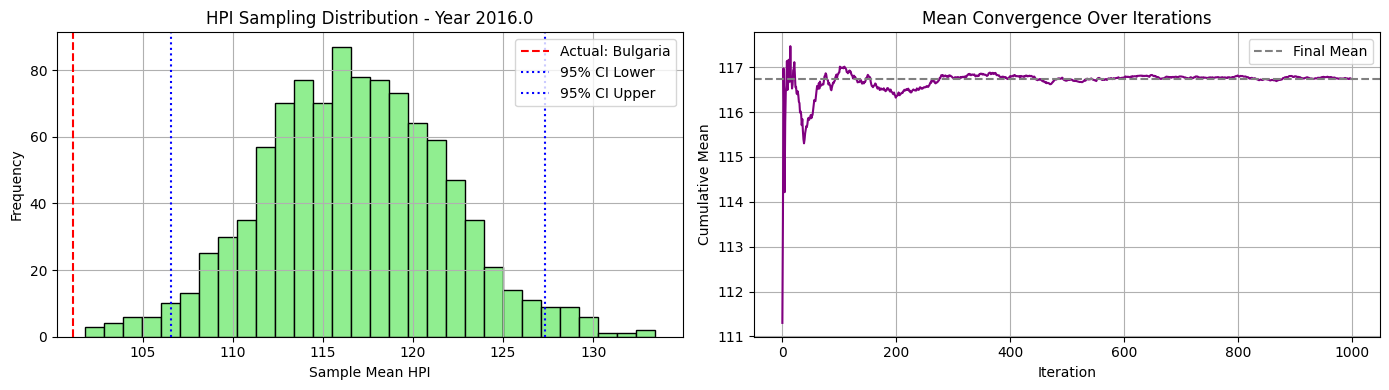


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66  94.84  83.98 172.91 109.02  83.98 112.44 156.44  83.98
 146.87 136.34 139.69 178.56 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  83.98 125.42]


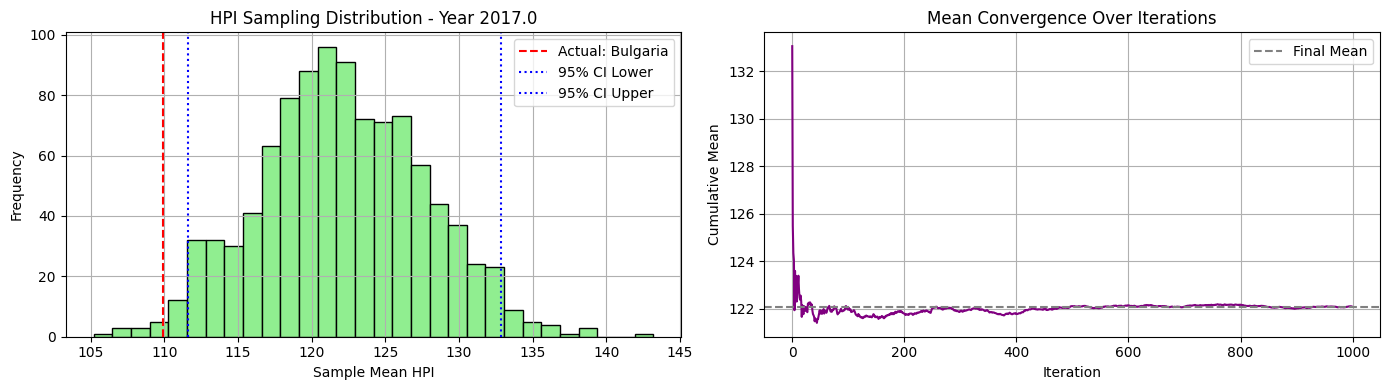


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 100.59  88.13 183.13 110.06  88.13 123.96 155.14  88.13
 160.92 146.29 149.55 183.82 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   88.13 129.16]


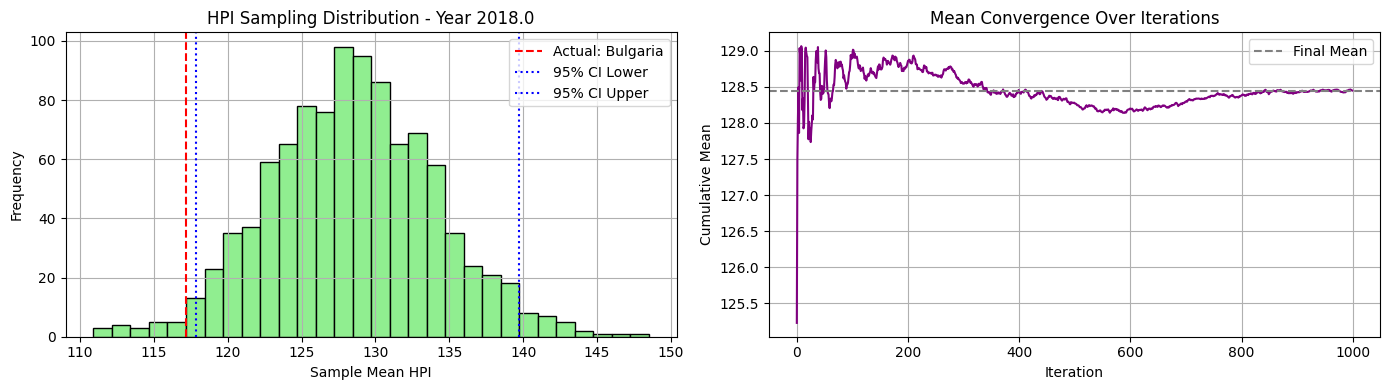


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 109.64  92.69 195.98 110.52  92.69 126.85 158.06  92.69
 175.33 156.3  164.68 195.98 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  92.69 133.99]


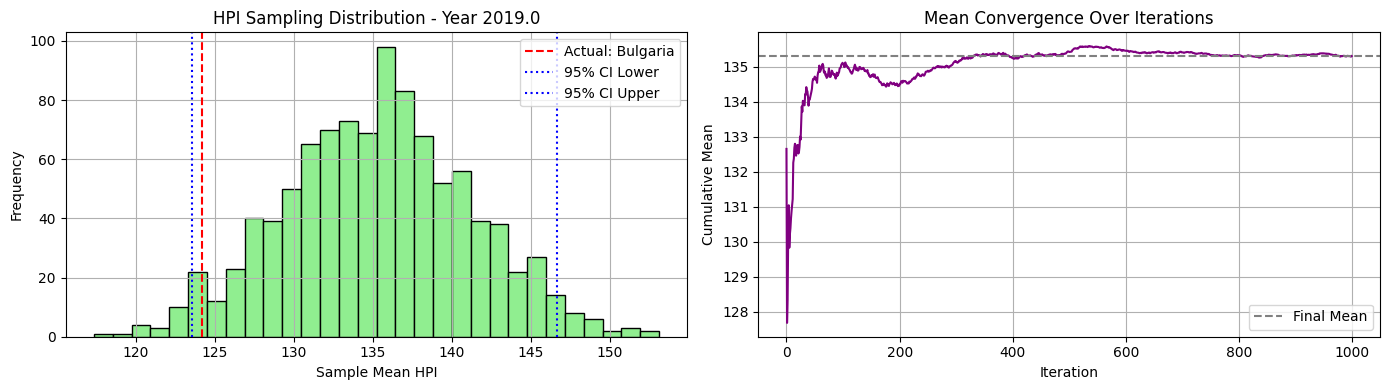


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 118.06  94.76 203.12 112.49  94.76 127.24 162.9   94.76
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74  94.76 137.31]


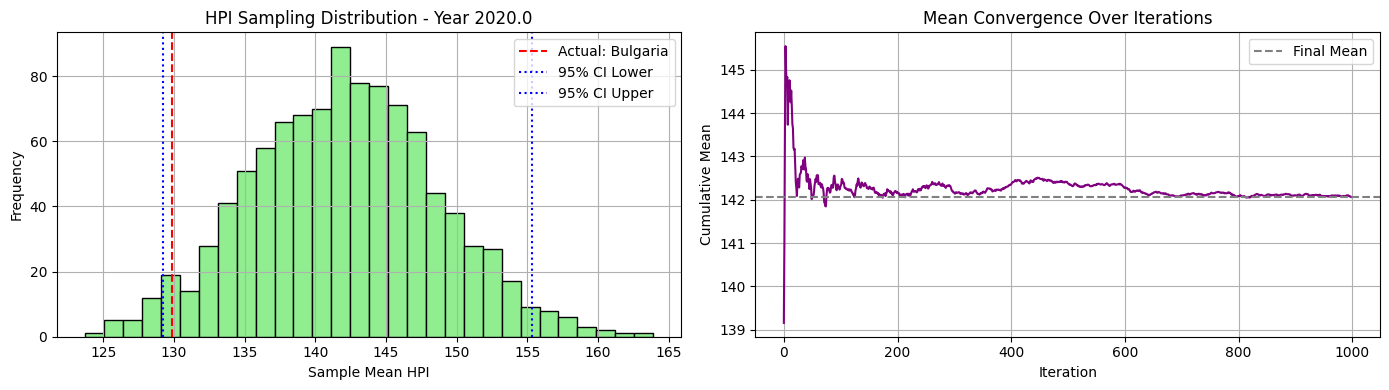


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 126.64  98.24 222.1  117.62  98.24 137.77 176.65  98.24
 201.18 194.58 214.81 200.69 148.74 147.93 222.1  173.6  157.27 112.34
 125.04 158.94 129.1   98.24 145.16]


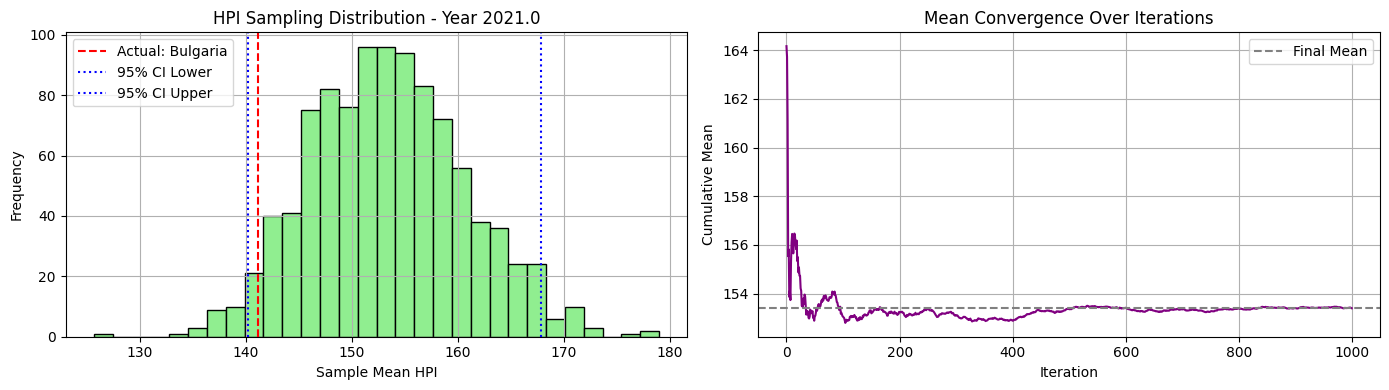


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 145.44 105.52 249.69 118.98 105.52 154.73 207.16 105.52
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 105.52 154.42]


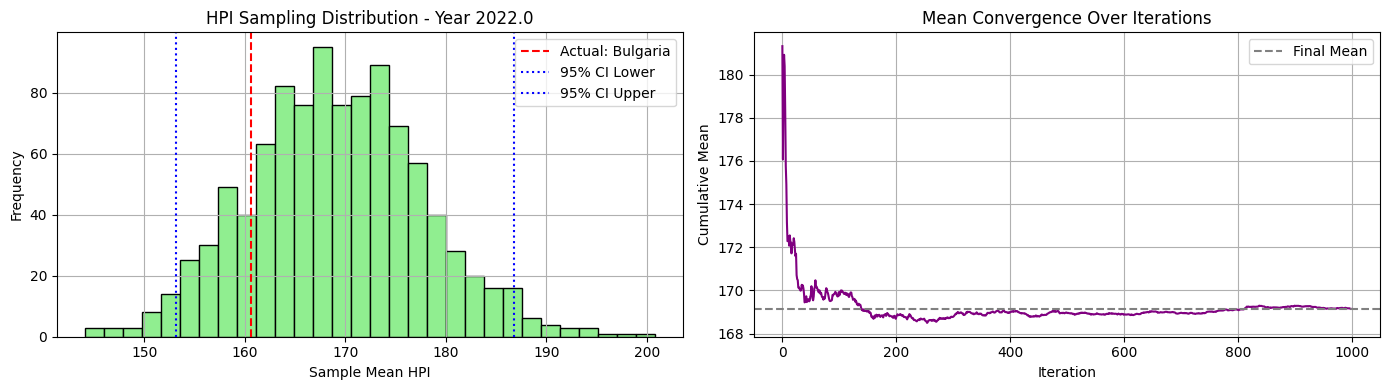


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 162.82 109.76 254.38 112.27 109.76 159.48 214.23 109.76
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 109.76 157.81]


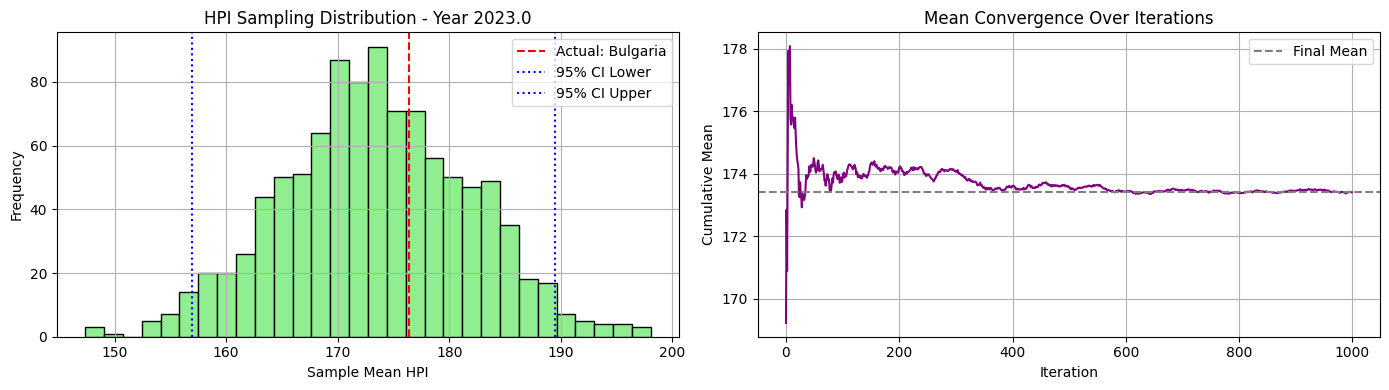


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 179.7  108.31 279.12 108.31 108.31 173.07 224.54 108.31
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


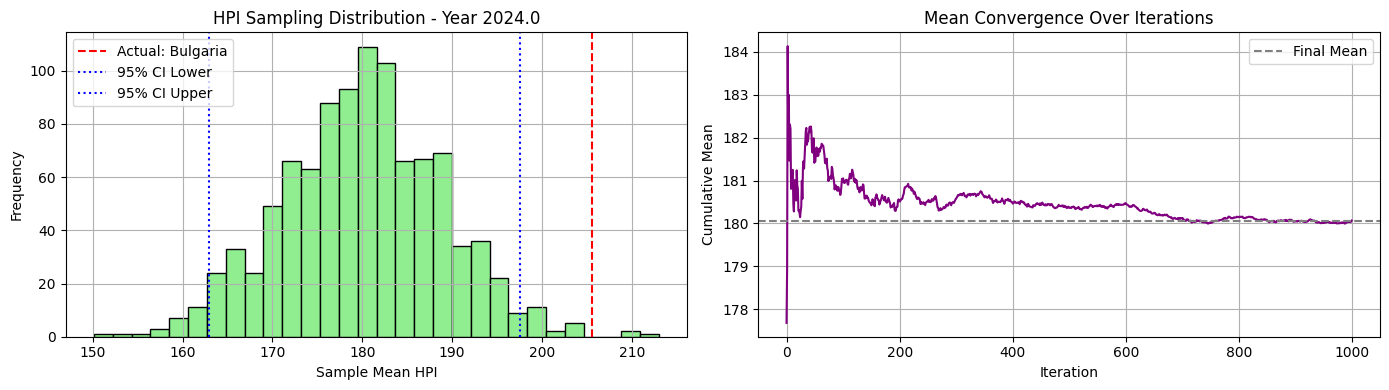

In [99]:
synthetic_c2_ni20_maxi500_h2_32_00, excluded_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_00 = estimate_hpi_by_cluster_sampling(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=32)

🔍 Cluster 1 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Brazil', 'Chile', 'Colombia', 'Czech-Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Serbia', 'South-Africa', 'South-Korea', 'Sweden', 'Thailand', 'United-Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100.]


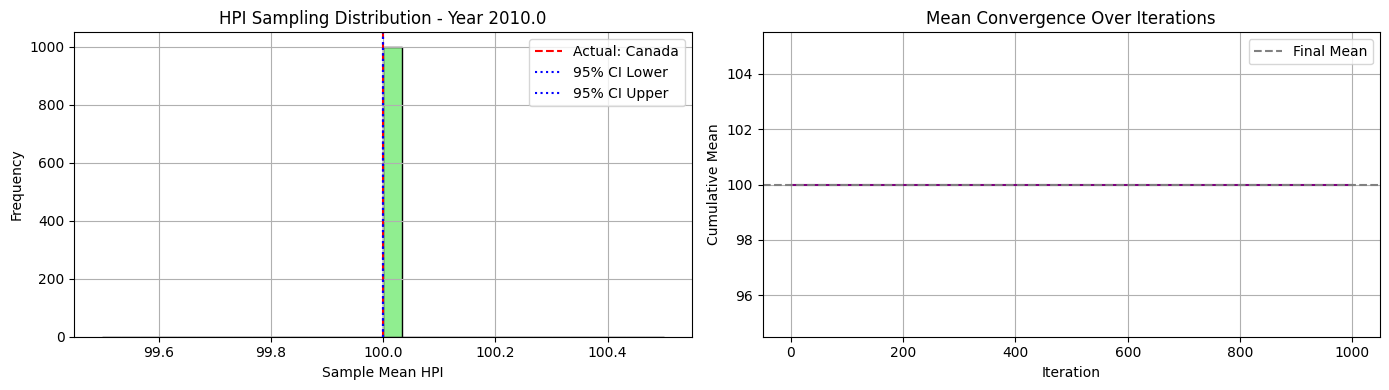


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 110.52 107.89 100.02  98.29 105.69 102.42  96.56 100.07
 105.8  108.01 105.57 100.08  97.62 103.59 105.23 102.58 104.26  98.54
  97.24]


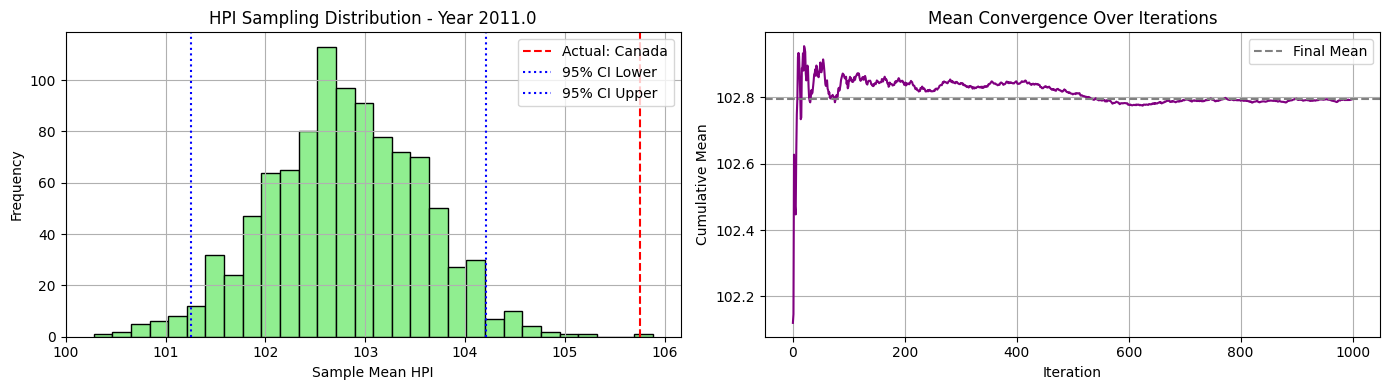


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 124.02 118.79  98.56  95.67 105.11 105.48  92.98  99.19
 109.17 115.34 114.94  96.58  95.68 108.41 108.25 103.86 107.63  98.92
 101.82]


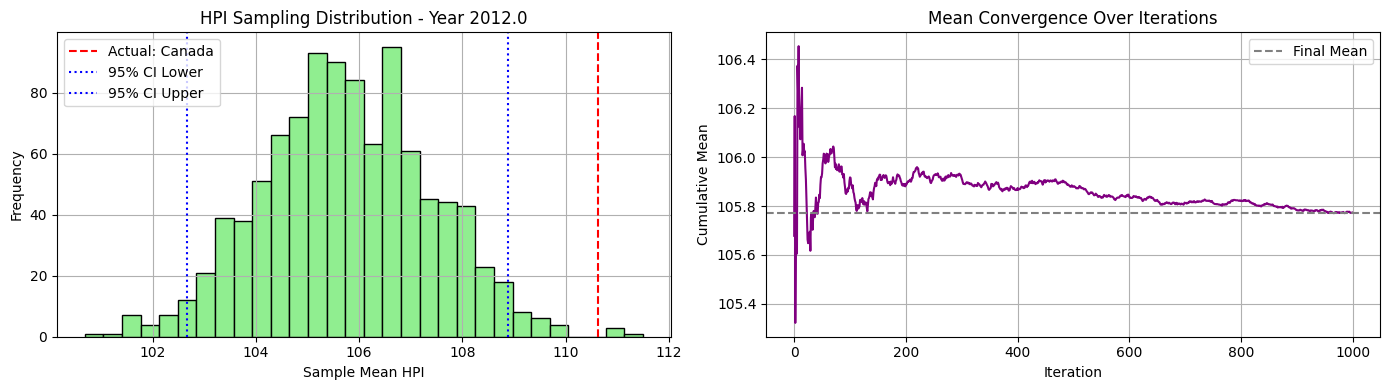


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 136.52 130.06  98.58  99.37 103.13 108.68  90.58 100.81
 114.75 119.98 127.86  92.35  90.62 115.41 107.8  109.22 115.99 101.46
 111.83]


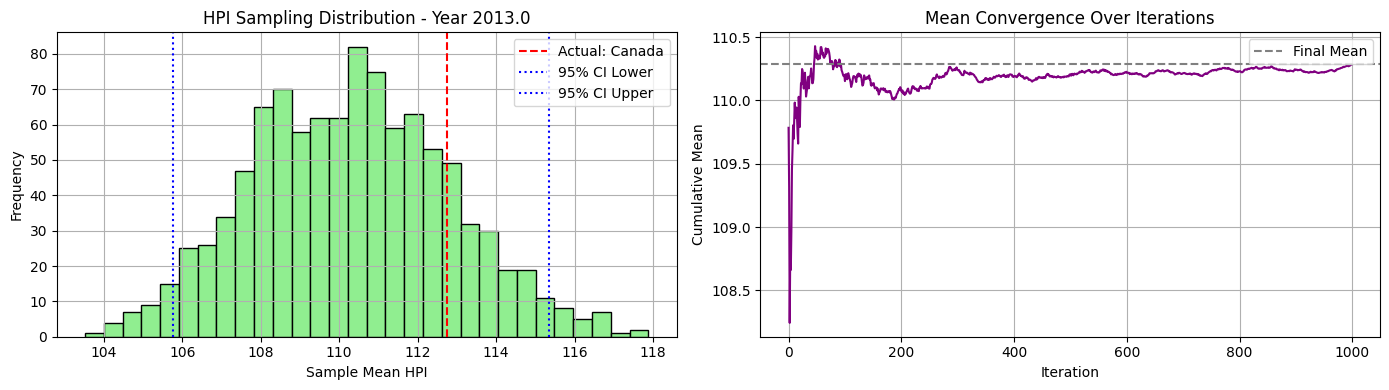


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 151.67 140.75 101.   103.12 101.58 111.85  94.37 102.38
 119.64 123.24 142.76  93.27  95.77 123.99 109.43 119.52 127.07 109.6
 118.88]


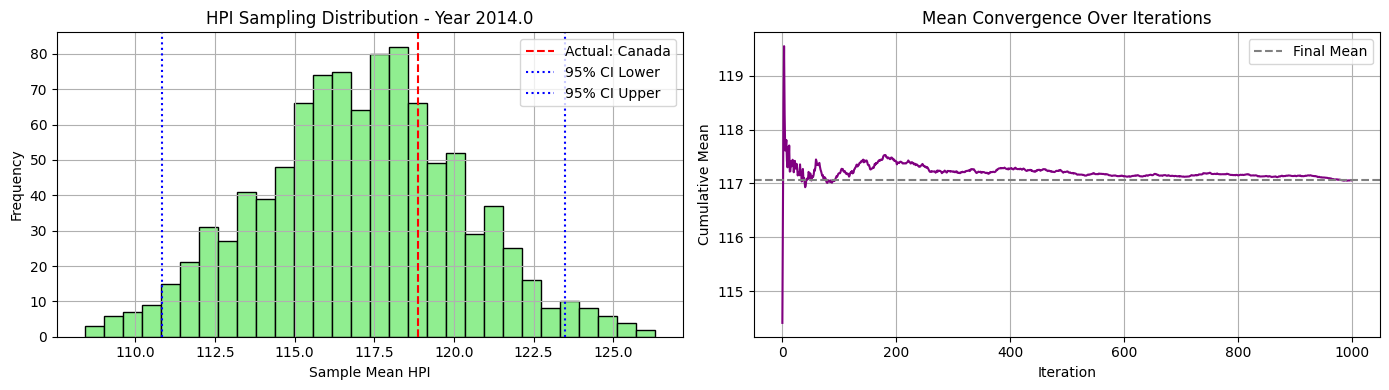


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 157.04 152.93 105.01 110.29 100.22 117.12 106.75 104.86
 129.39 130.76 157.04  94.69  99.5  131.8  113.08 135.2  136.   116.12
 125.18]


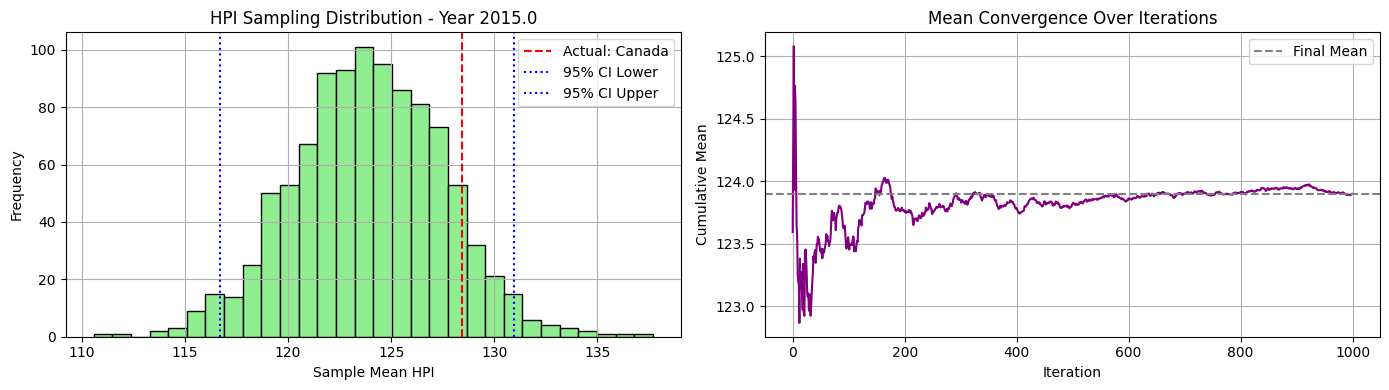


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 167.48 167.48 112.52 115.5  101.25 125.93 121.03 107.18
 138.82 139.95 167.48  96.44 110.62 138.22 116.09 146.34 142.4  124.27
 131.88]


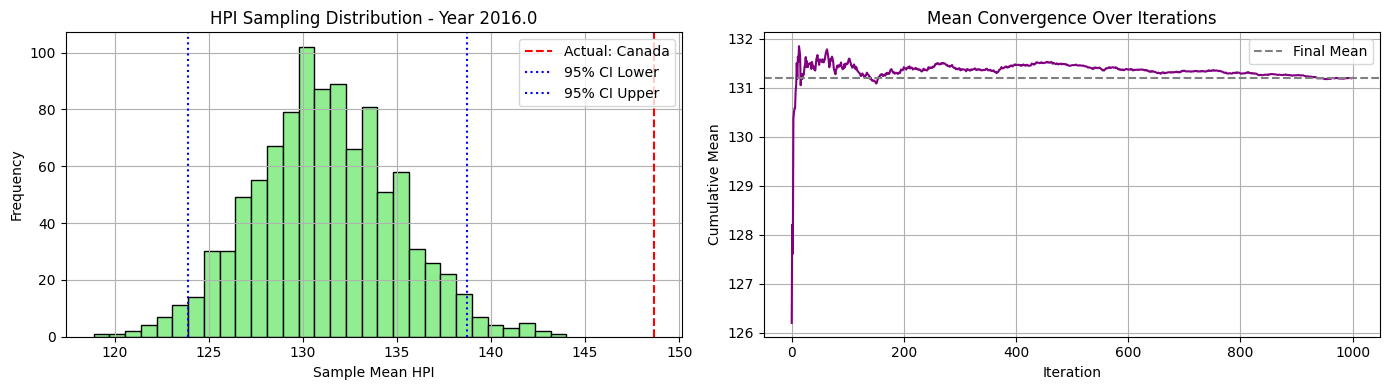


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 178.56 178.56 125.7  120.63 104.46 133.62 135.84 109.91
 149.69 146.91 178.56 100.16 115.3  143.94 117.6  156.06 146.48 129.93
 139.61]


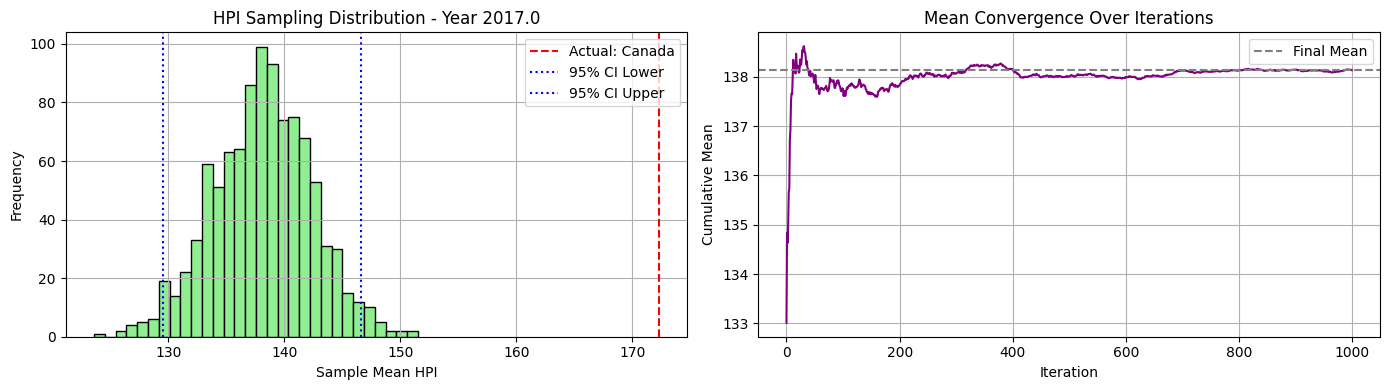


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 183.82 183.82 136.52 126.31 107.52 142.52 155.3  112.04
 162.97 149.04 183.82 106.75 123.06 148.96 120.22 154.6  153.9  134.04
 147.35]


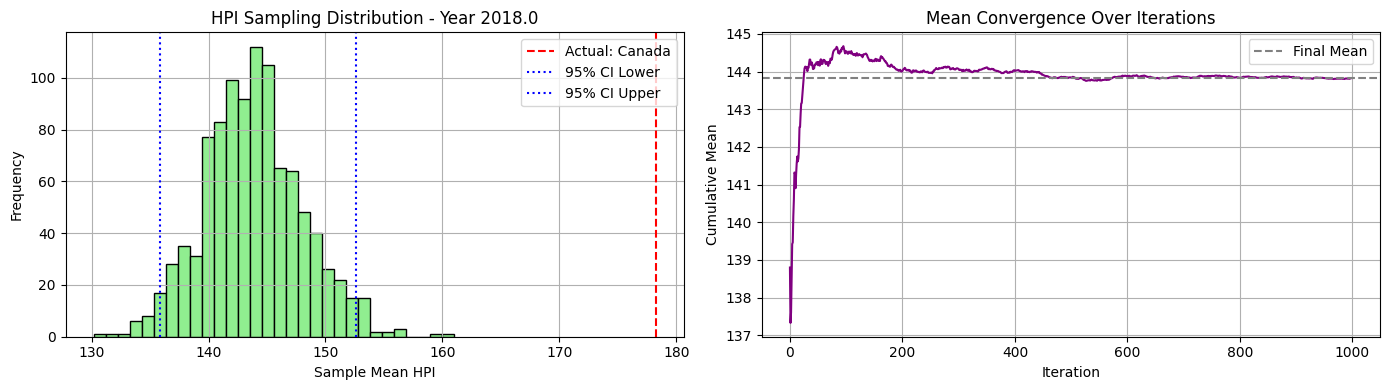


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 195.98 195.98 149.02 129.62 111.1  150.75 181.64 113.84
 176.92 152.73 195.26 116.01 135.77 152.69 121.93 158.44 155.1  135.37
 153.14]


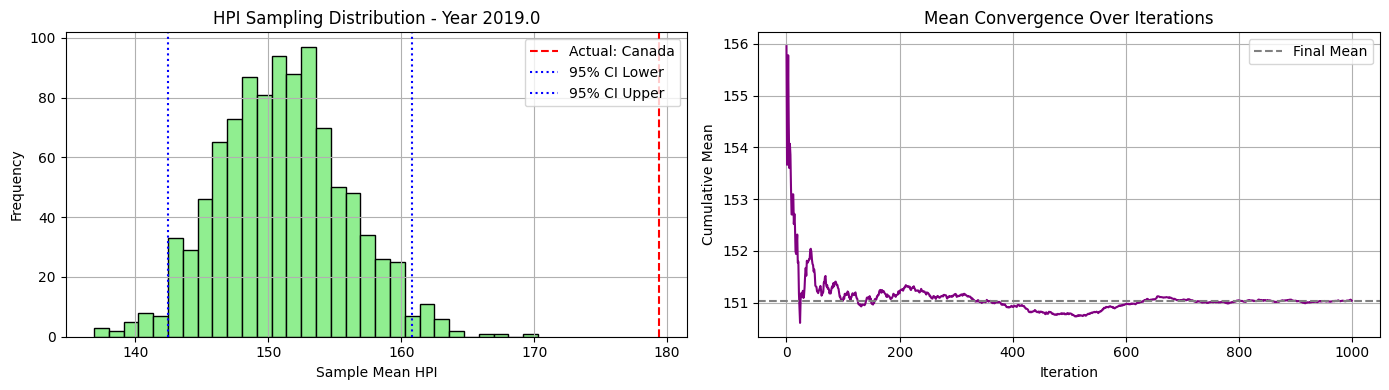


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 203.12 203.12 161.56 136.24 116.89 162.48 190.63 113.93
 187.18 159.24 203.12 128.18 149.28 156.31 126.56 165.09 160.6  139.24
 163.52]


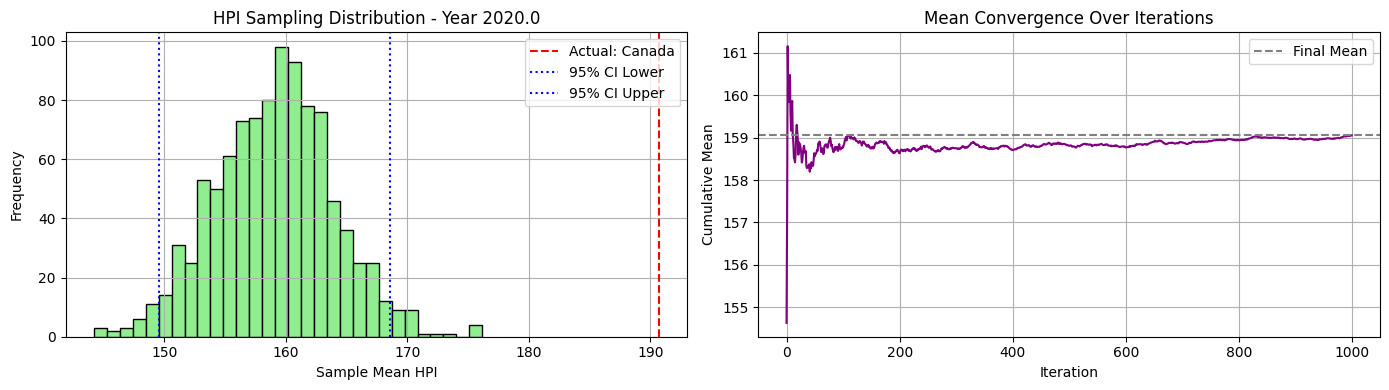


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 222.1  214.9  193.46 152.2  124.38 181.28 222.1  120.7
 201.94 175.91 211.74 139.92 166.04 166.82 143.73 181.79 164.23 150.58
 188.56]


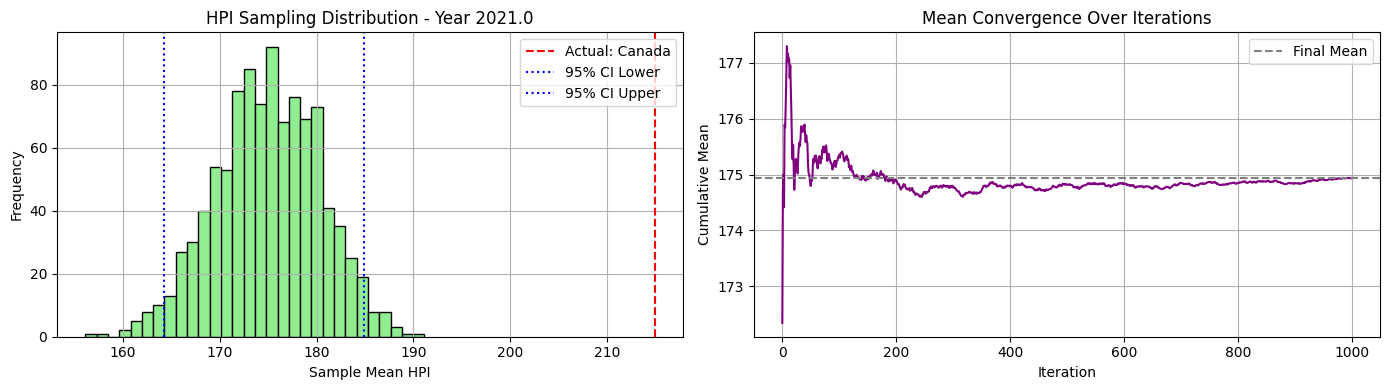


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 249.69 230.   226.15 151.49 132.1  190.42 249.69 130.84
 219.93 185.13 223.73 156.43 191.49 174.03 153.22 188.27 169.16 164.55
 213.  ]


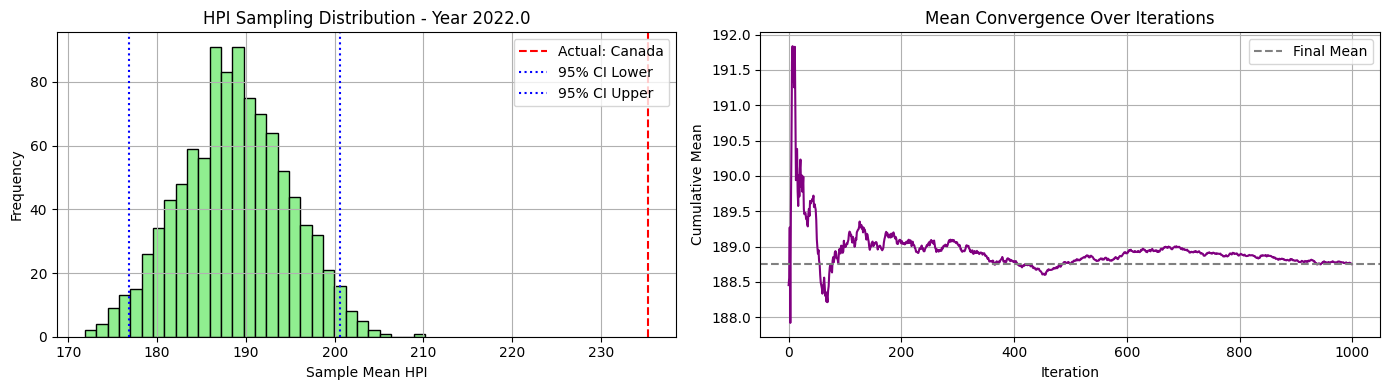


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 254.38 245.75 222.4  151.24 131.52 174.25 254.38 134.8
 243.89 184.12 248.04 170.23 209.99 176.62 143.99 178.36 174.79 165.
 221.72]


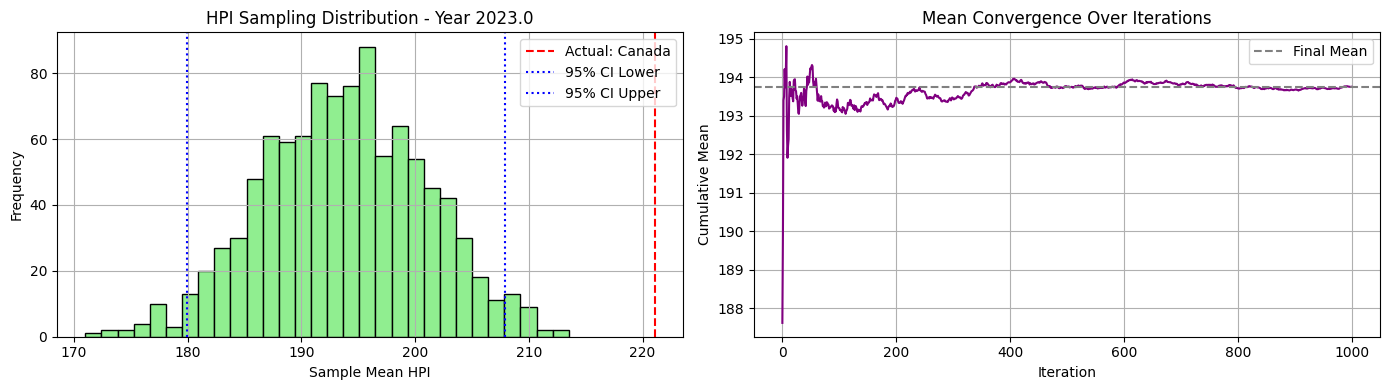


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 279.12 269.02 233.42 156.73 126.68 171.5  279.12 138.61
 266.38 189.05 256.03 195.72 220.7  178.1  142.46 178.49 178.06 166.38
 231.23]


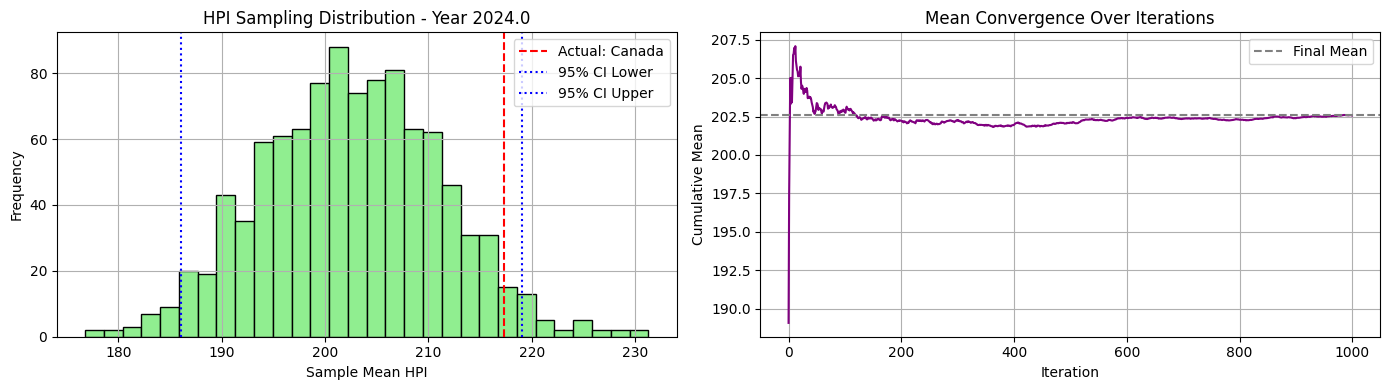

In [100]:
synthetic_c2_ni20_maxi500_h2_32_01, excluded_c2_ni20_maxi500_h2_32_01, actual_c2_ni20_maxi500_h2_32_01 = estimate_hpi_by_cluster_sampling(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=32)

### Sampling experiment with seed 43

🔍 Cluster 0 selected. Excluding country: Belgium
📊 Sampling from countries: ['Austria', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New-Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


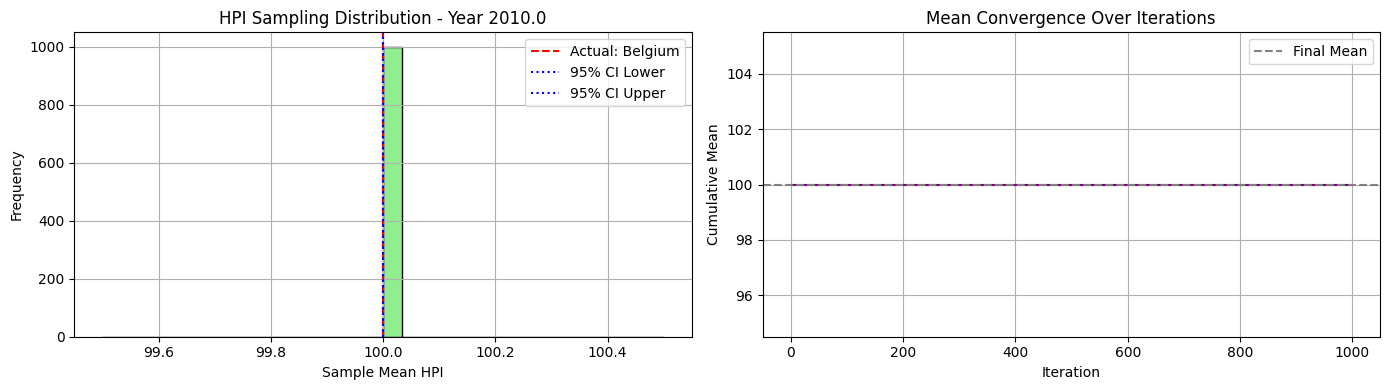


📅 Year 2011.0 - Available HPI values for sampling:
[104.22  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


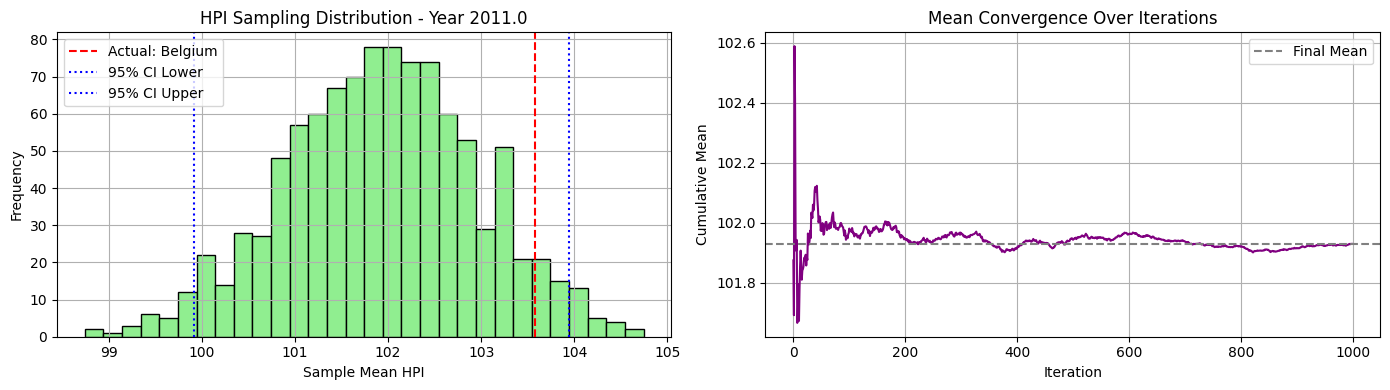


📅 Year 2012.0 - Available HPI values for sampling:
[117.13  92.69  98.62  91.54 116.34 105.64  83.51  83.51 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  83.51
 112.02  95.73  95.63  83.51 113.72]


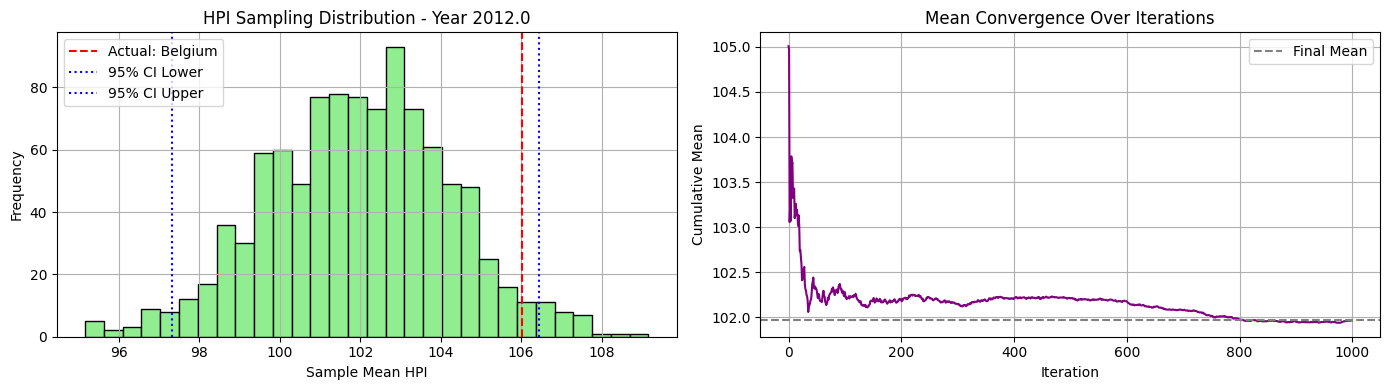


📅 Year 2013.0 - Available HPI values for sampling:
[122.59  90.65  94.7   85.58 128.77 106.87  83.06  83.06 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   83.06
 115.56  96.53  90.62  83.06 118.3 ]


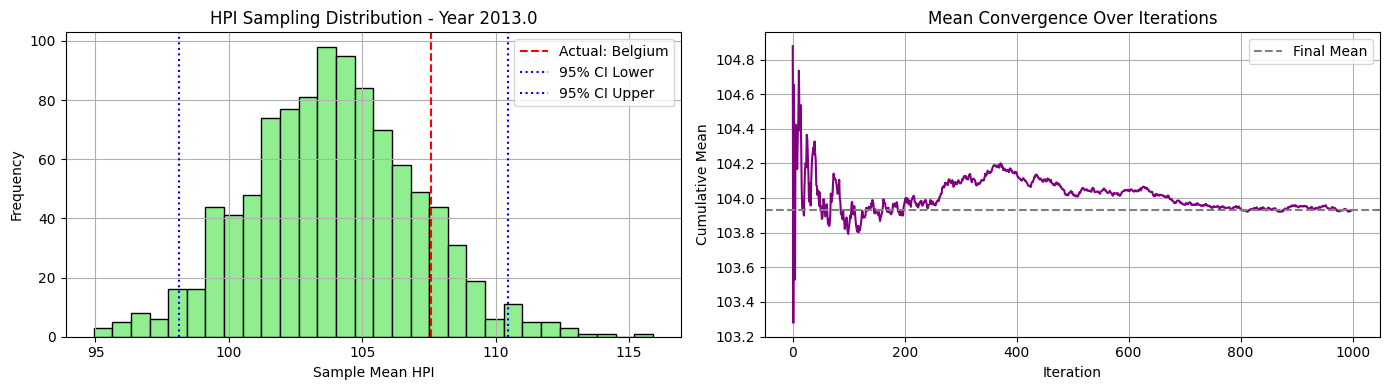


📅 Year 2014.0 - Available HPI values for sampling:
[126.79  91.95  93.19  81.38 146.41 106.5   81.38  84.66 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  81.38
 112.25  97.8   84.64  81.38 121.46]


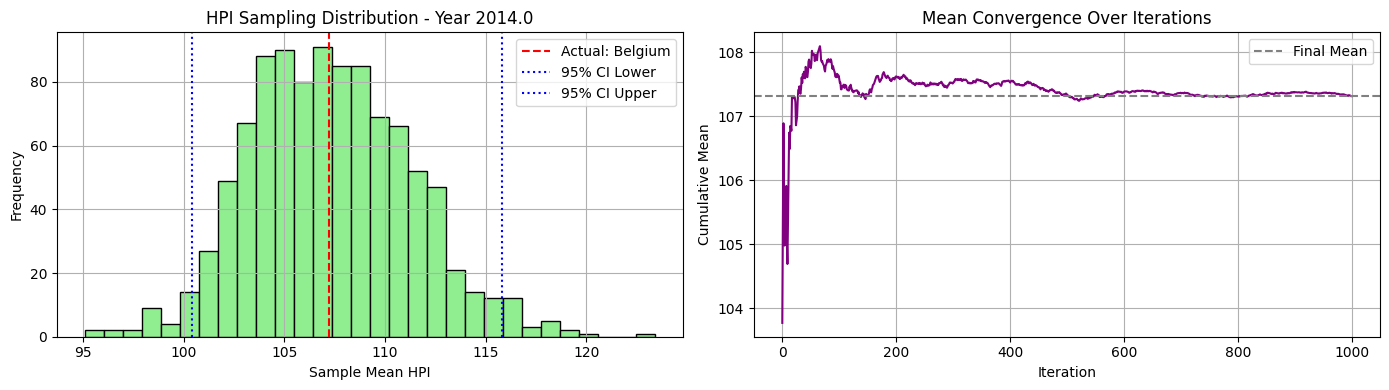


📅 Year 2015.0 - Available HPI values for sampling:
[132.06  94.51  90.54  83.68 156.46 106.5   83.68  94.36 140.12  84.67
 124.46 118.76 124.78 157.04 109.83  89.69 137.18 157.04  93.15  83.68
 107.92 103.    85.32  83.68 124.08]


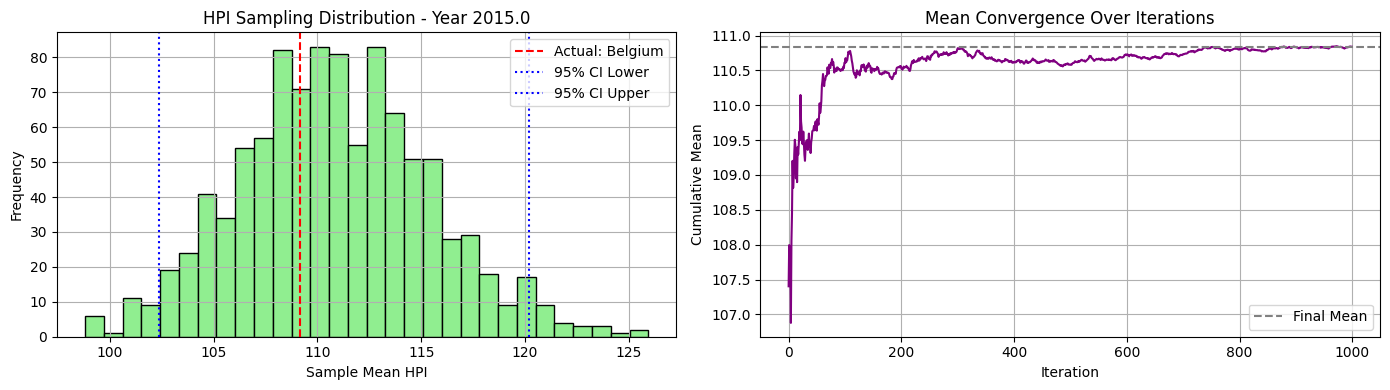


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 101.15  91.33  84.88 163.86 107.86  84.88 101.42 150.56  84.88
 135.02 125.16 132.28 167.48 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   84.88 124.32]


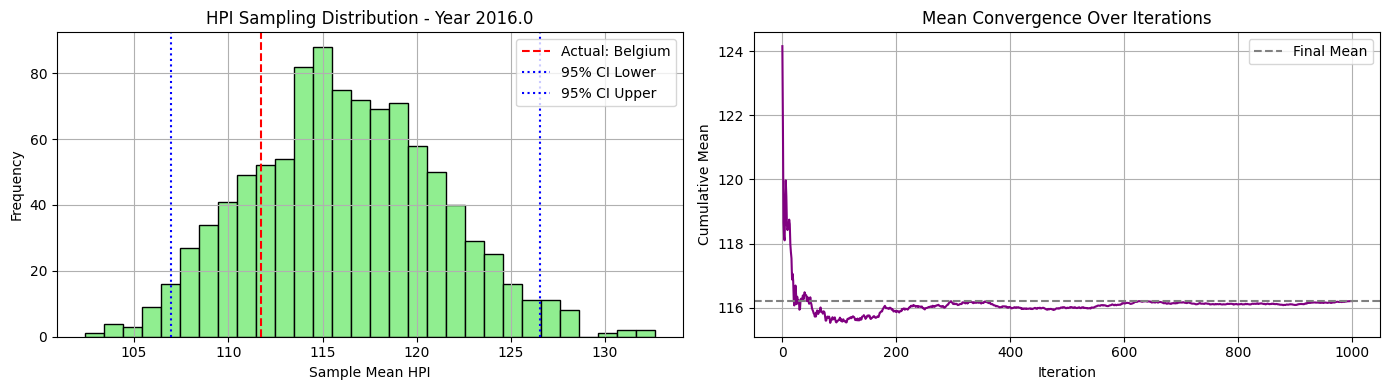


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 109.91  94.84  83.98 172.91 109.02  83.98 112.44 156.44  83.98
 146.87 136.34 139.69 178.56 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  83.98 125.42]


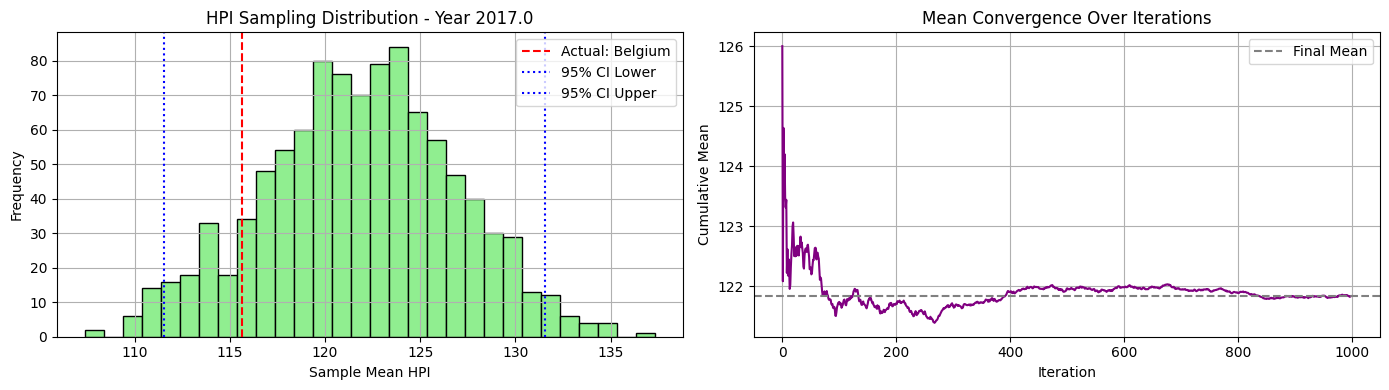


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 117.15 100.59  88.13 183.13 110.06  88.13 123.96 155.14  88.13
 160.92 146.29 149.55 183.82 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   88.13 129.16]


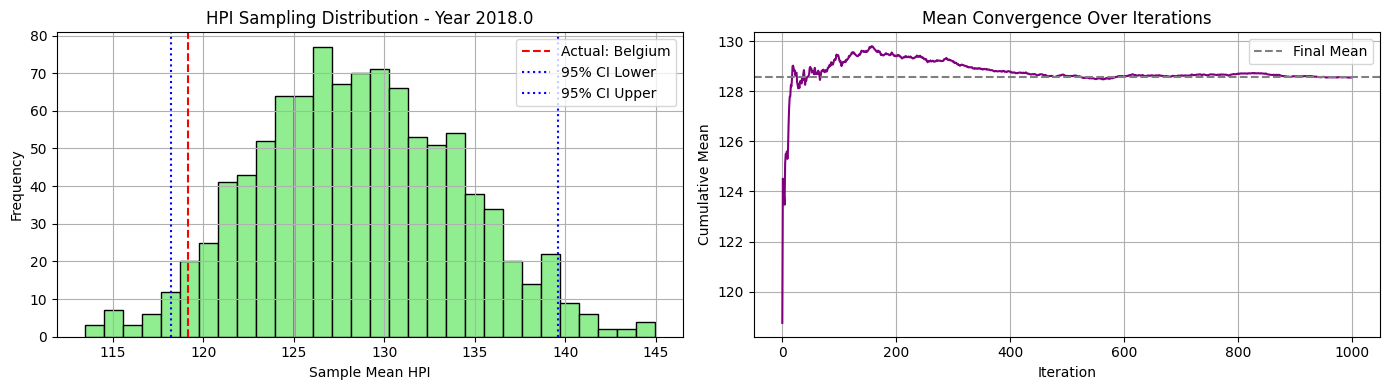


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 124.2  109.64  92.69 195.98 110.52  92.69 126.85 158.06  92.69
 175.33 156.3  164.68 195.98 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  92.69 133.99]


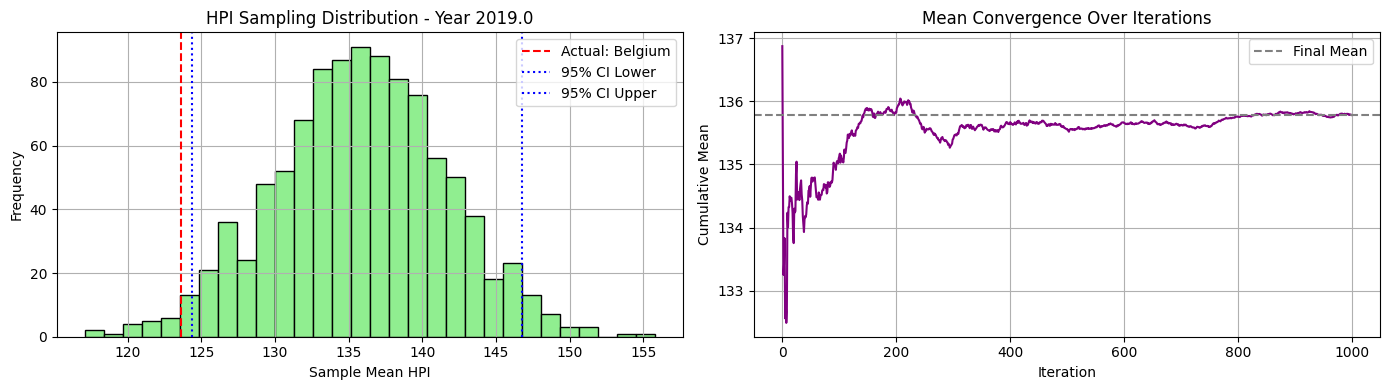


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 129.87 118.06  94.76 203.12 112.49  94.76 127.24 162.9   94.76
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74  94.76 137.31]


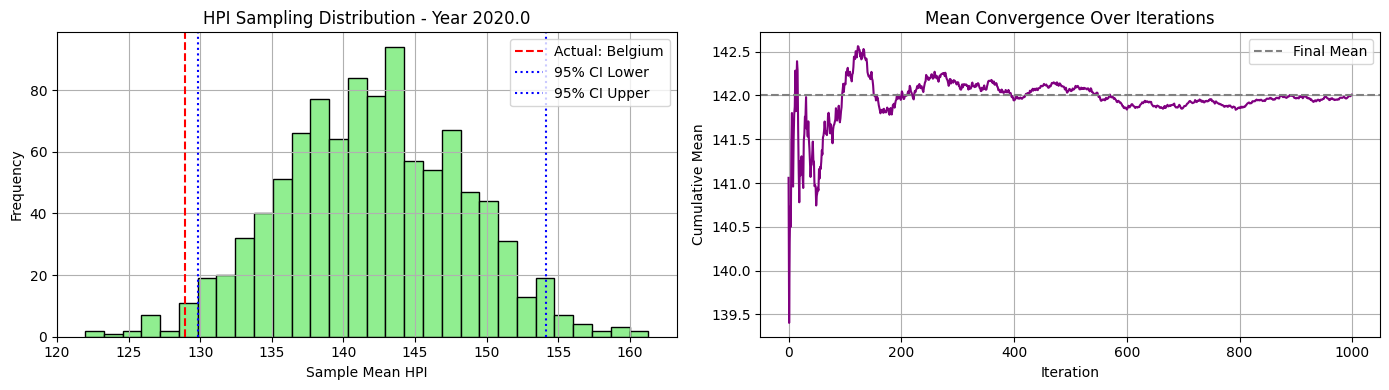


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 141.14 126.64  98.24 222.1  117.62  98.24 137.77 176.65  98.24
 201.18 194.58 214.81 200.69 148.74 147.93 222.1  173.6  157.27 112.34
 125.04 158.94 129.1   98.24 145.16]


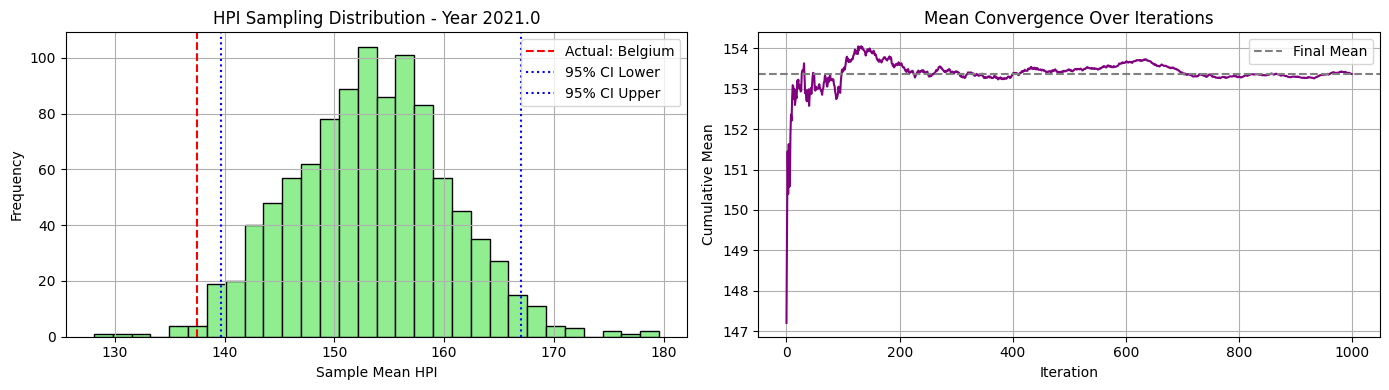


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 160.59 145.44 105.52 249.69 118.98 105.52 154.73 207.16 105.52
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 105.52 154.42]


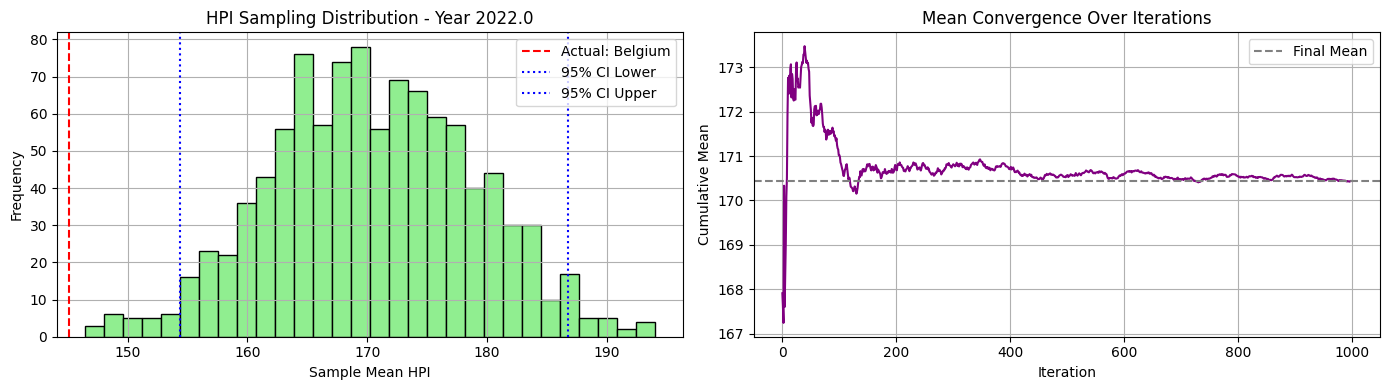


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 176.43 162.82 109.76 254.38 112.27 109.76 159.48 214.23 109.76
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 109.76 157.81]


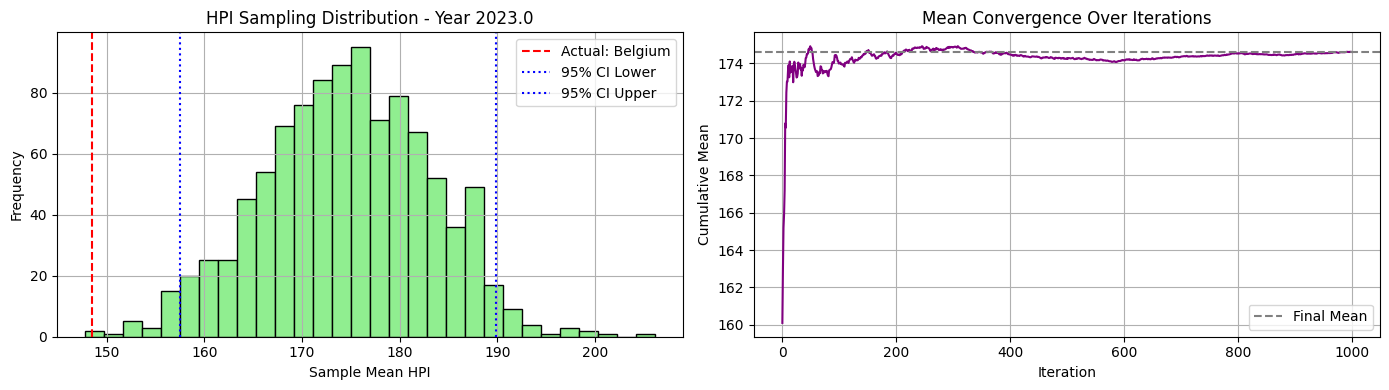


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 205.53 179.7  108.31 279.12 108.31 108.31 173.07 224.54 108.31
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


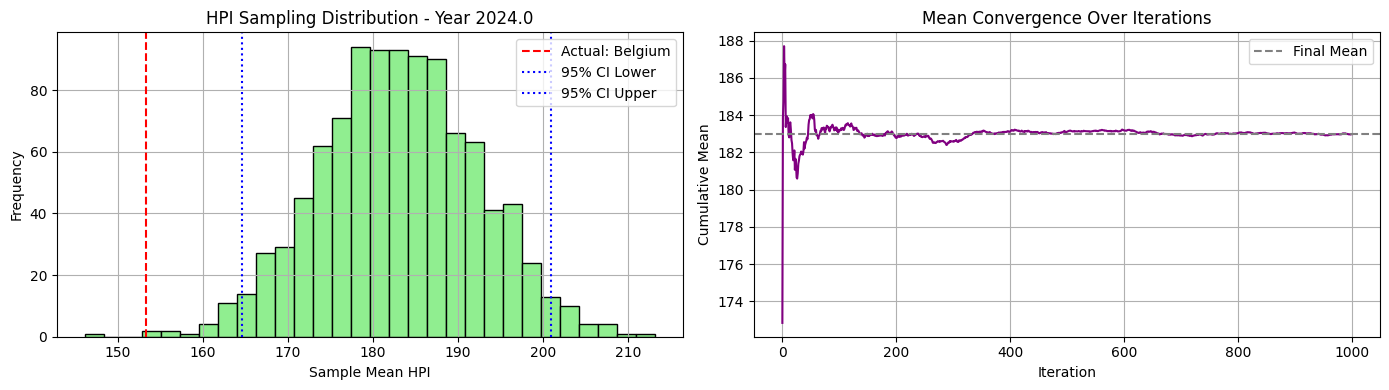

In [101]:
synthetic_c2_ni20_maxi500_h2_43_00, excluded_c2_ni20_maxi500_h2_43_00, actual_c2_ni20_maxi500_h2_43_00 = estimate_hpi_by_cluster_sampling(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=43)

🔍 Cluster 1 selected. Excluding country: Brazil
📊 Sampling from countries: ['Australia', 'Canada', 'Chile', 'Colombia', 'Czech-Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Serbia', 'South-Africa', 'South-Korea', 'Sweden', 'Thailand', 'United-Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100.]


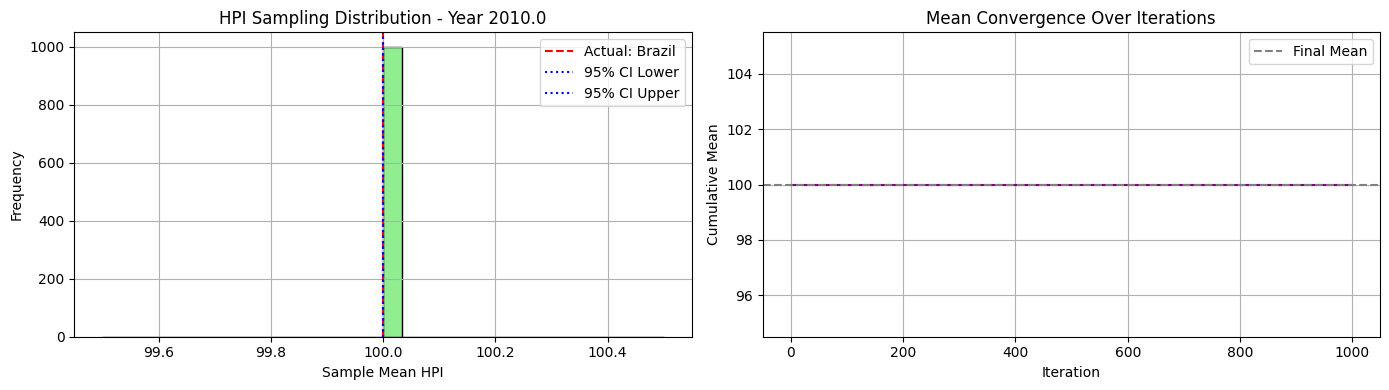


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 105.75 110.52 107.89 100.02  98.29 105.69 102.42  96.56 100.07
 105.8  108.01 105.57 100.08  97.62 103.59 105.23 102.58 104.26  98.54
  97.24]


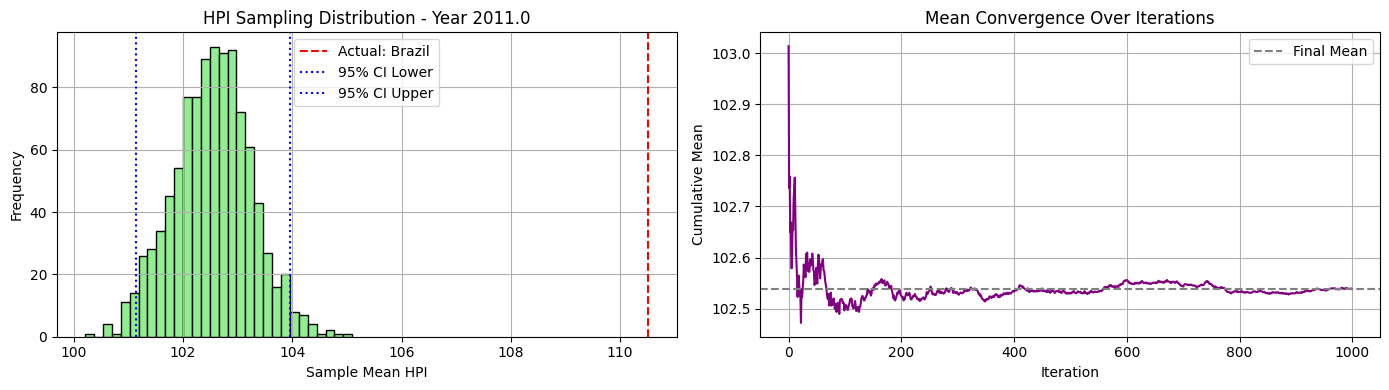


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 110.62 124.02 118.79  98.56  95.67 105.11 105.48  92.98  99.19
 109.17 115.34 114.94  96.58  95.68 108.41 108.25 103.86 107.63  98.92
 101.82]


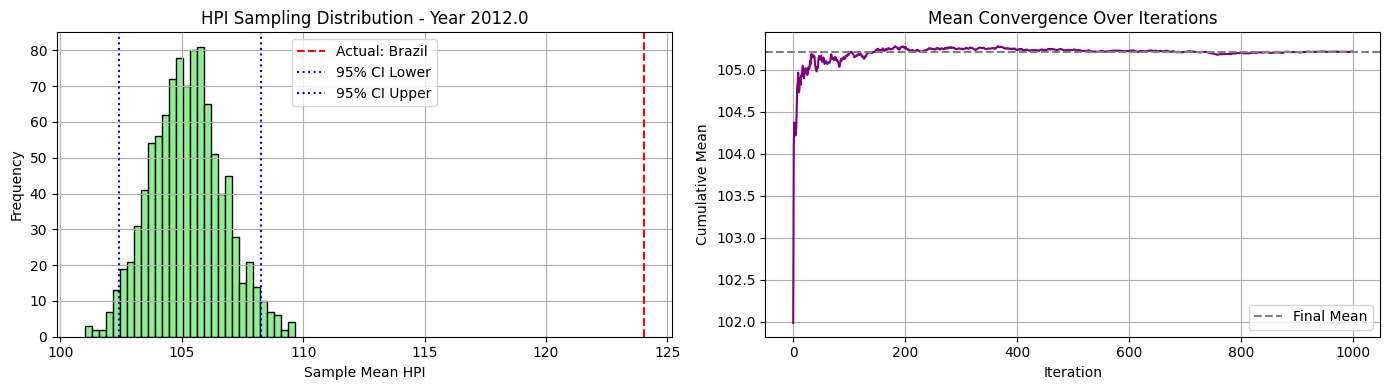


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 112.76 136.52 130.06  98.58  99.37 103.13 108.68  90.58 100.81
 114.75 119.98 127.86  92.35  90.62 115.41 107.8  109.22 115.99 101.46
 111.83]


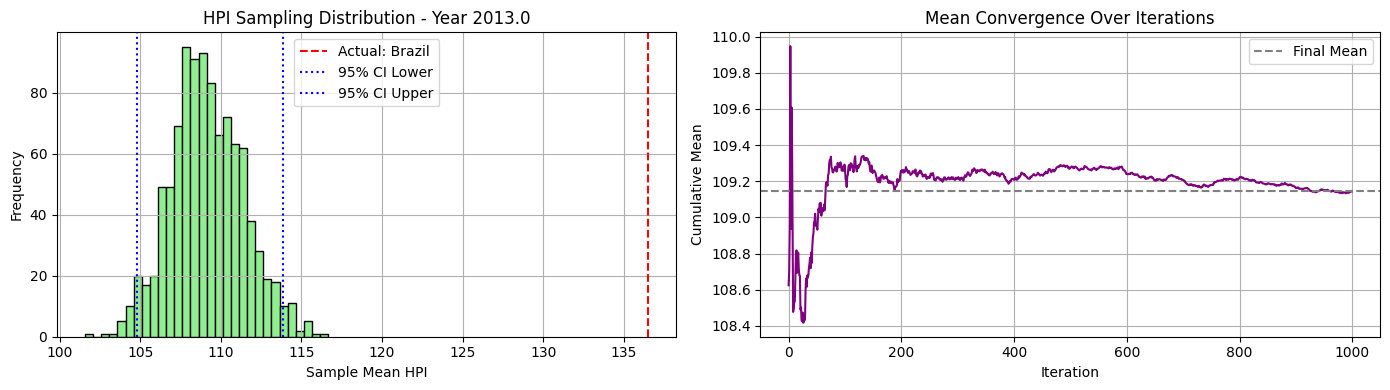


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 118.86 151.67 140.75 101.   103.12 101.58 111.85  94.37 102.38
 119.64 123.24 142.76  93.27  95.77 123.99 109.43 119.52 127.07 109.6
 118.88]


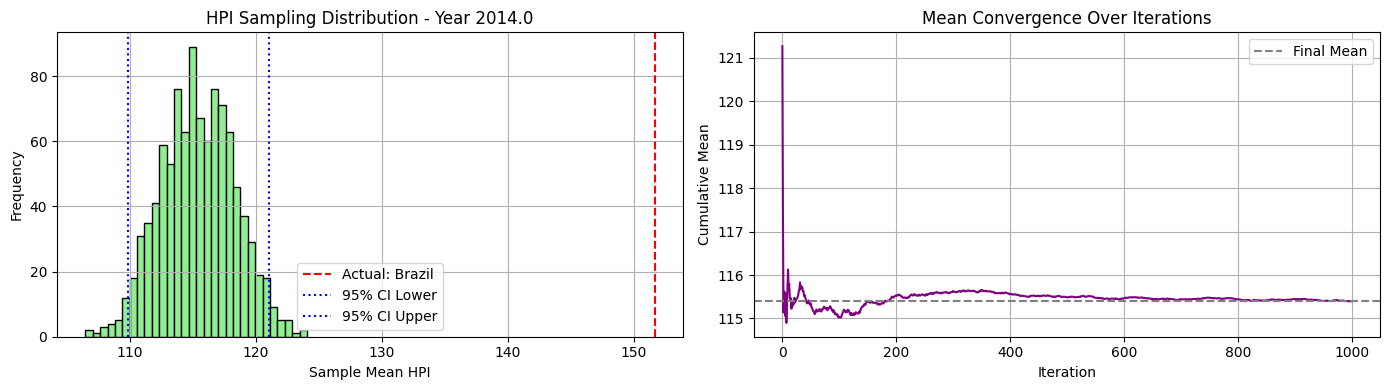


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 128.43 157.04 152.93 105.01 110.29 100.22 117.12 106.75 104.86
 129.39 130.76 157.04  94.69  99.5  131.8  113.08 135.2  136.   116.12
 125.18]


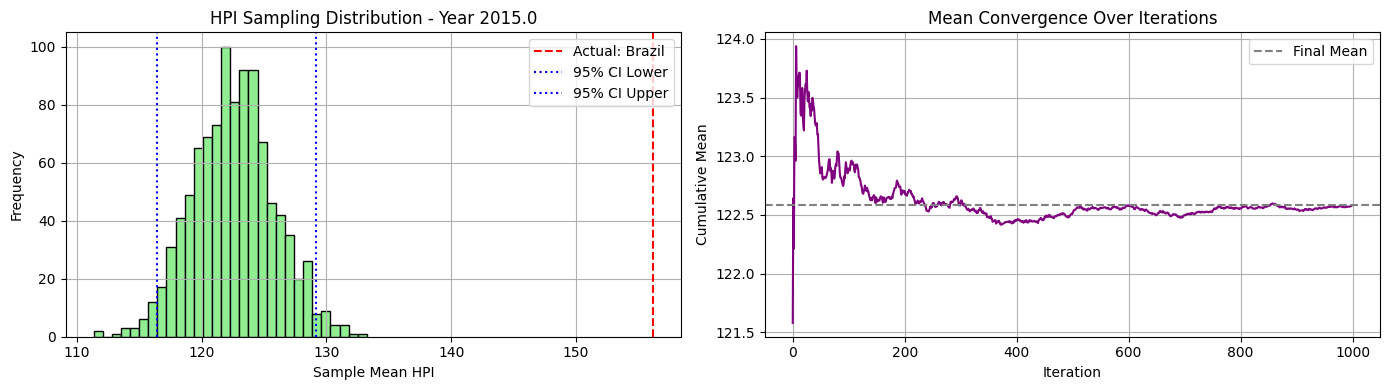


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 148.66 167.48 167.48 112.52 115.5  101.25 125.93 121.03 107.18
 138.82 139.95 167.48  96.44 110.62 138.22 116.09 146.34 142.4  124.27
 131.88]


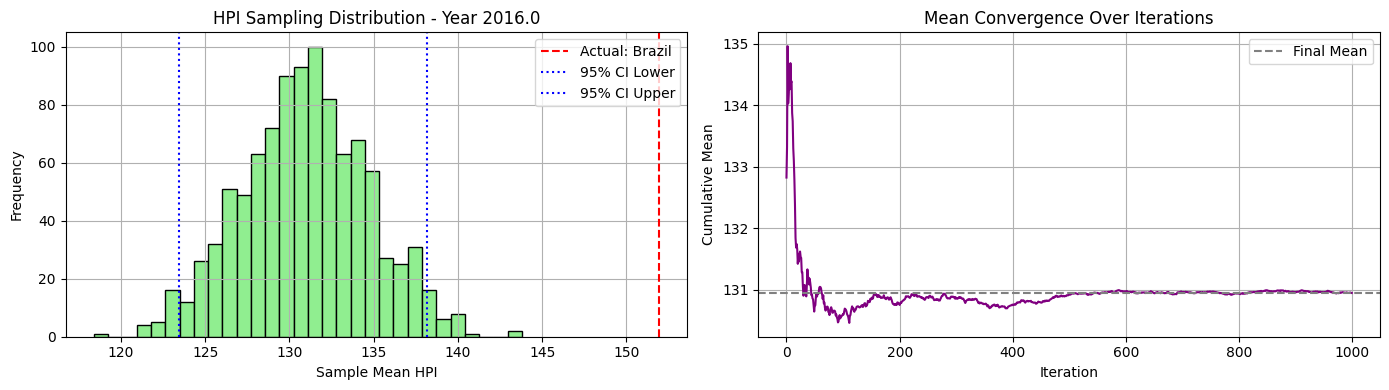


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 172.3  178.56 178.56 125.7  120.63 104.46 133.62 135.84 109.91
 149.69 146.91 178.56 100.16 115.3  143.94 117.6  156.06 146.48 129.93
 139.61]


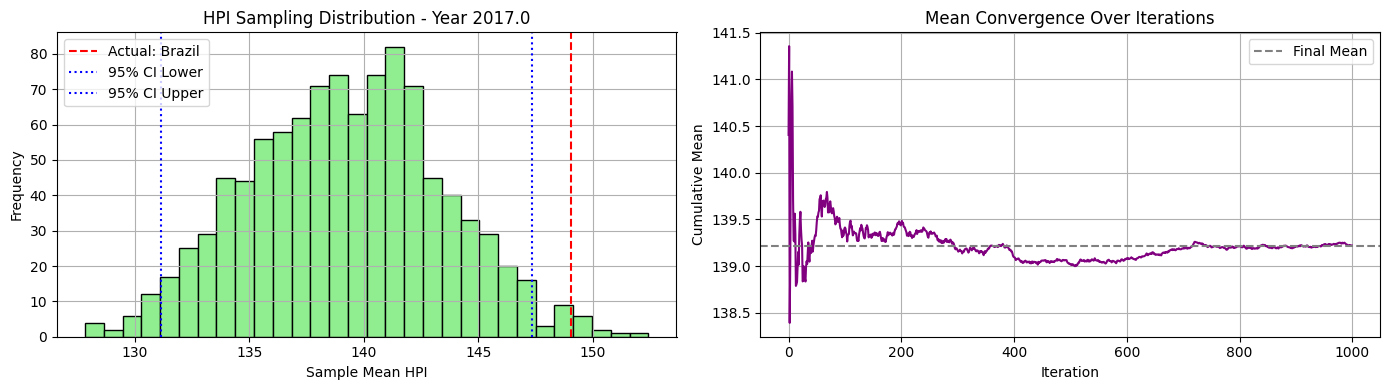


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  178.24 183.82 183.82 136.52 126.31 107.52 142.52 155.3  112.04
 162.97 149.04 183.82 106.75 123.06 148.96 120.22 154.6  153.9  134.04
 147.35]


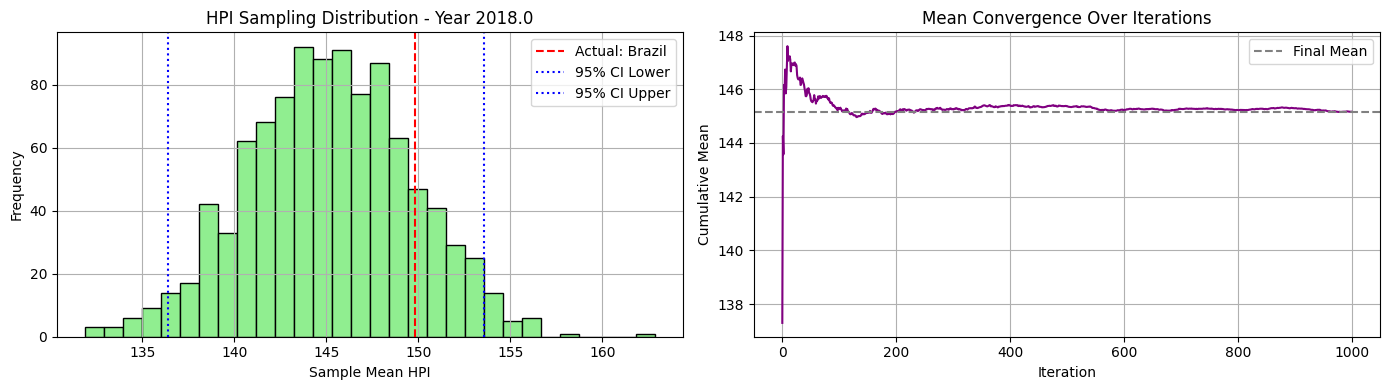


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 179.4  195.98 195.98 149.02 129.62 111.1  150.75 181.64 113.84
 176.92 152.73 195.26 116.01 135.77 152.69 121.93 158.44 155.1  135.37
 153.14]


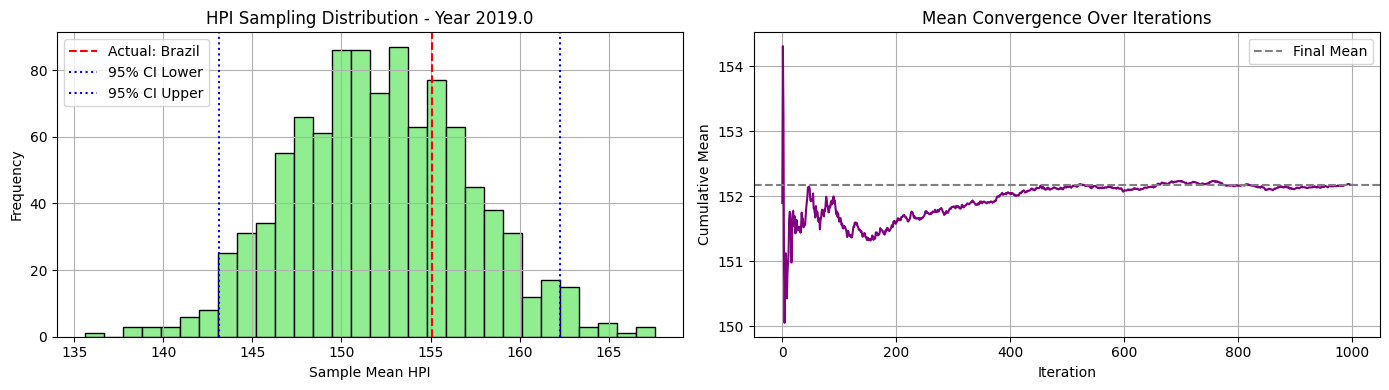


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 190.73 203.12 203.12 161.56 136.24 116.89 162.48 190.63 113.93
 187.18 159.24 203.12 128.18 149.28 156.31 126.56 165.09 160.6  139.24
 163.52]


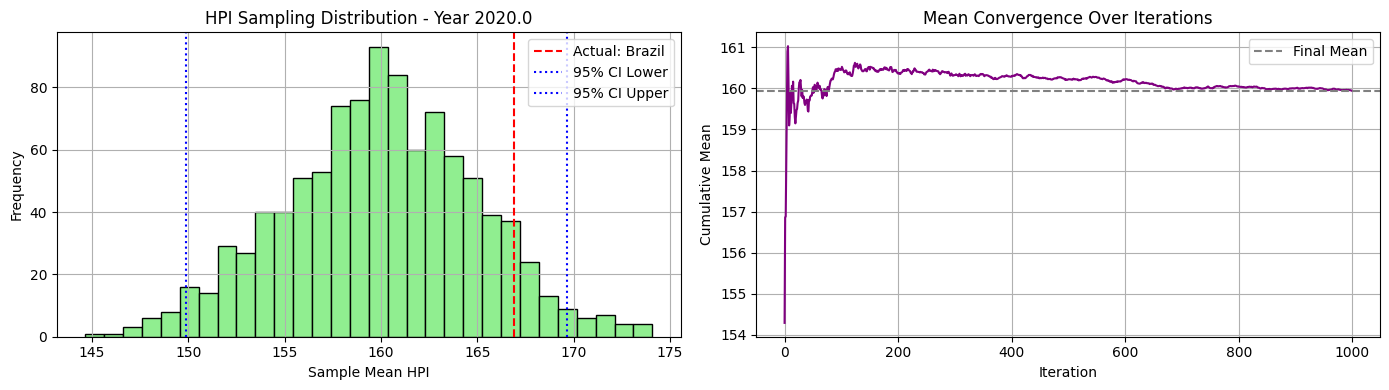


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 214.88 222.1  214.9  193.46 152.2  124.38 181.28 222.1  120.7
 201.94 175.91 211.74 139.92 166.04 166.82 143.73 181.79 164.23 150.58
 188.56]


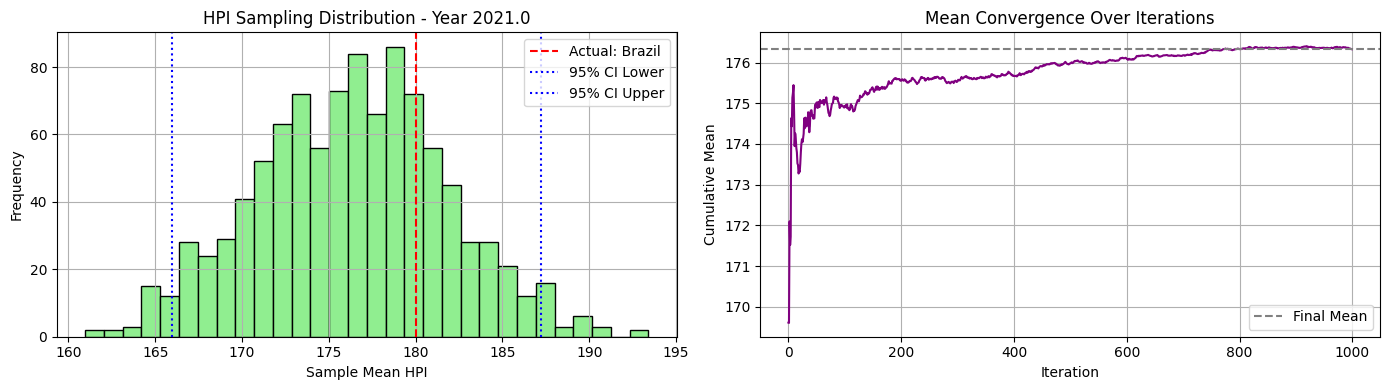


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 235.32 249.69 230.   226.15 151.49 132.1  190.42 249.69 130.84
 219.93 185.13 223.73 156.43 191.49 174.03 153.22 188.27 169.16 164.55
 213.  ]


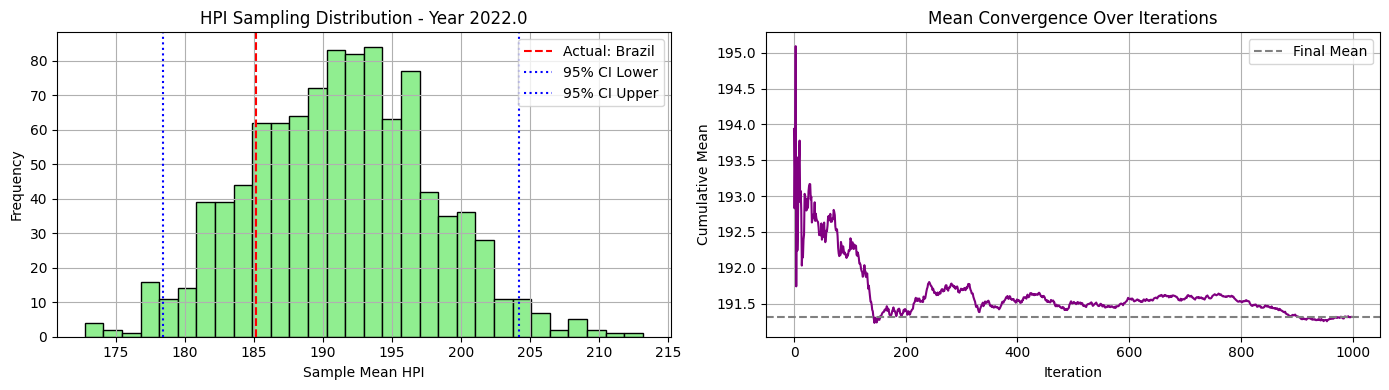


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 221.05 254.38 245.75 222.4  151.24 131.52 174.25 254.38 134.8
 243.89 184.12 248.04 170.23 209.99 176.62 143.99 178.36 174.79 165.
 221.72]


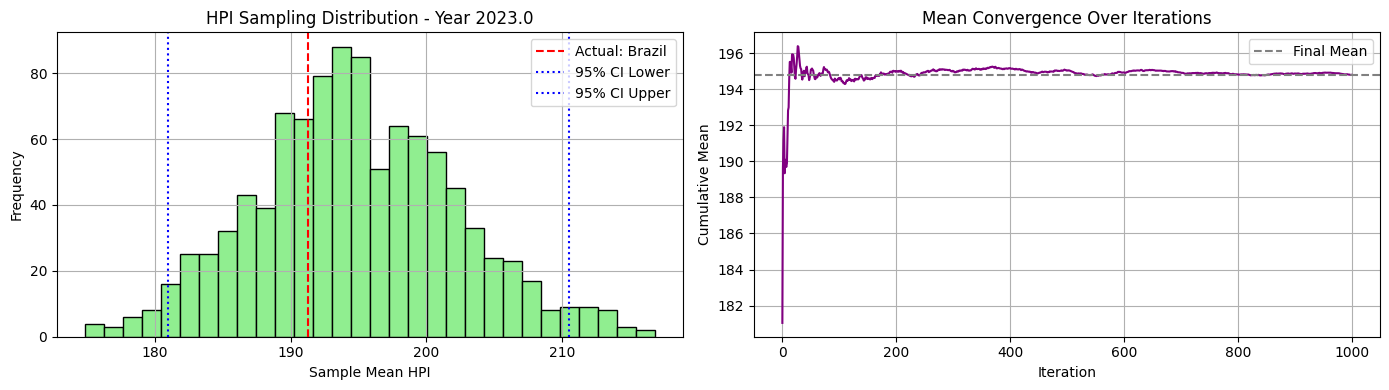


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 217.35 279.12 269.02 233.42 156.73 126.68 171.5  279.12 138.61
 266.38 189.05 256.03 195.72 220.7  178.1  142.46 178.49 178.06 166.38
 231.23]


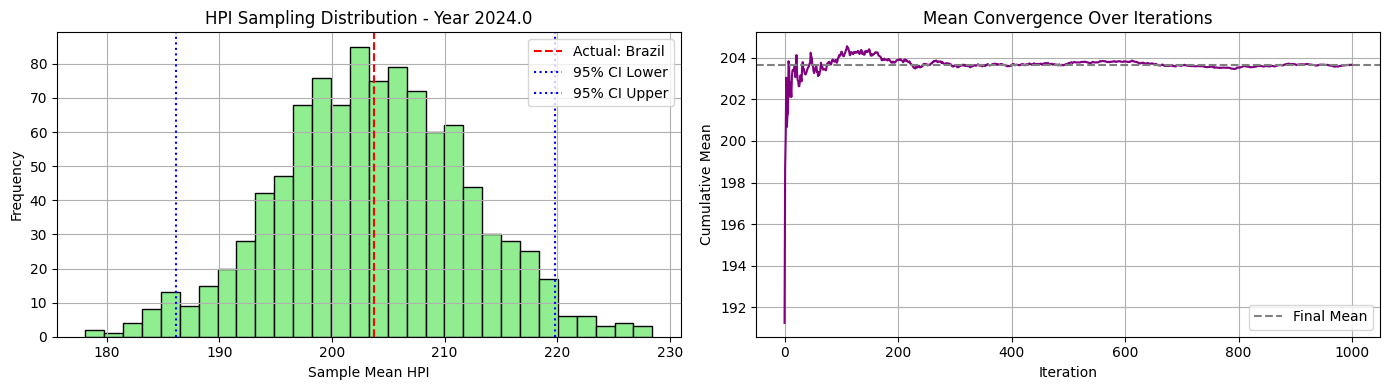

In [102]:
synthetic_c2_ni20_maxi500_h2_43_01, excluded_c2_ni20_maxi500_h2_43_01, actual_c2_ni20_maxi500_h2_43_01 = estimate_hpi_by_cluster_sampling(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=43)

### Sampling experiment with seed 52

🔍 Cluster 0 selected. Excluding country: Ireland
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New-Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


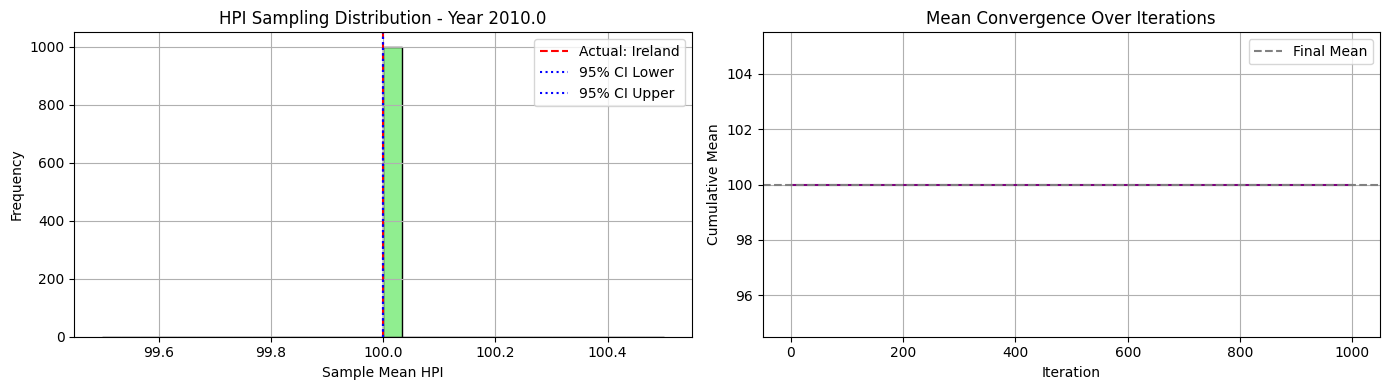


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16  96.68 108.47 103.17  94.53 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


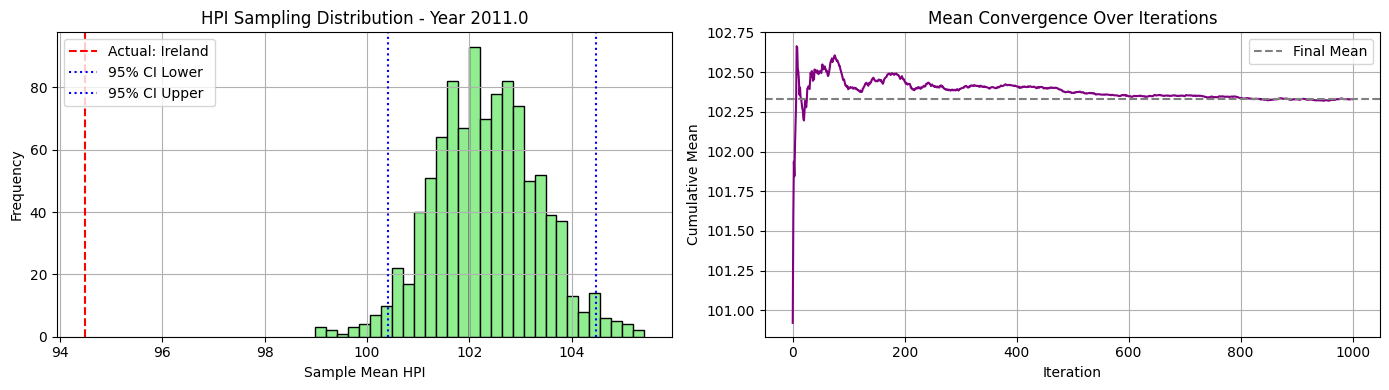


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  91.54 116.34 105.64  83.51 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  83.51
 112.02  95.73  95.63  83.51 113.72]


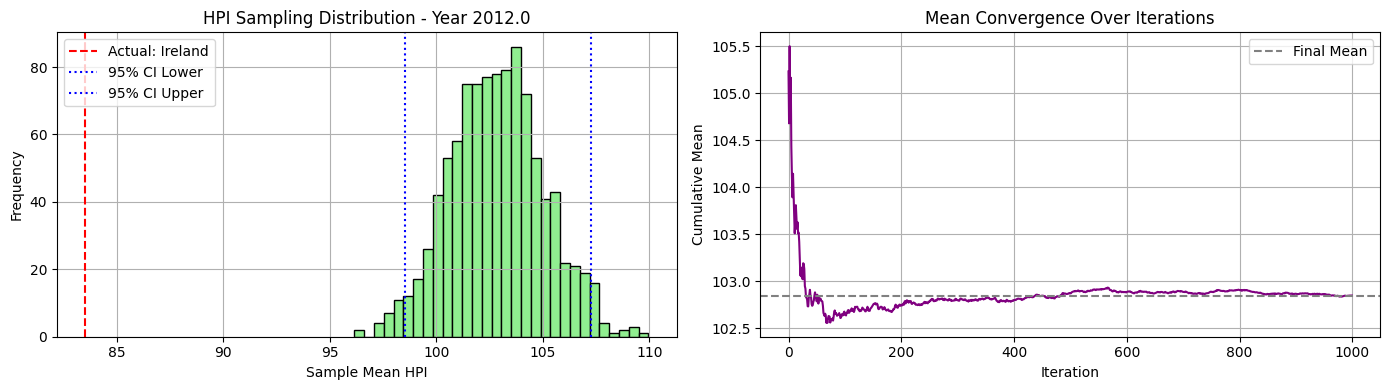


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   85.58 128.77 106.87  83.06 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   83.06
 115.56  96.53  90.62  83.06 118.3 ]


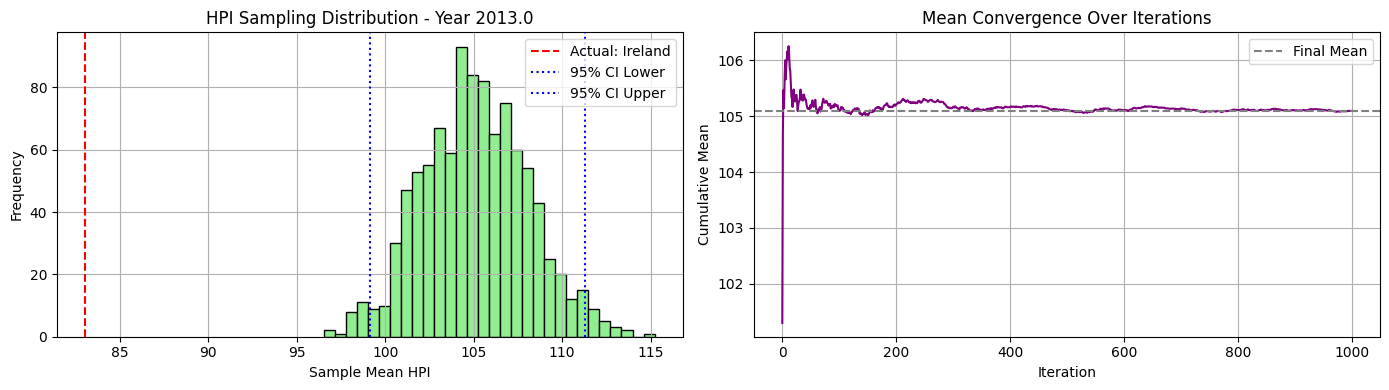


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19  81.38 146.41 106.5   81.38 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  81.38
 112.25  97.8   84.64  81.38 121.46]


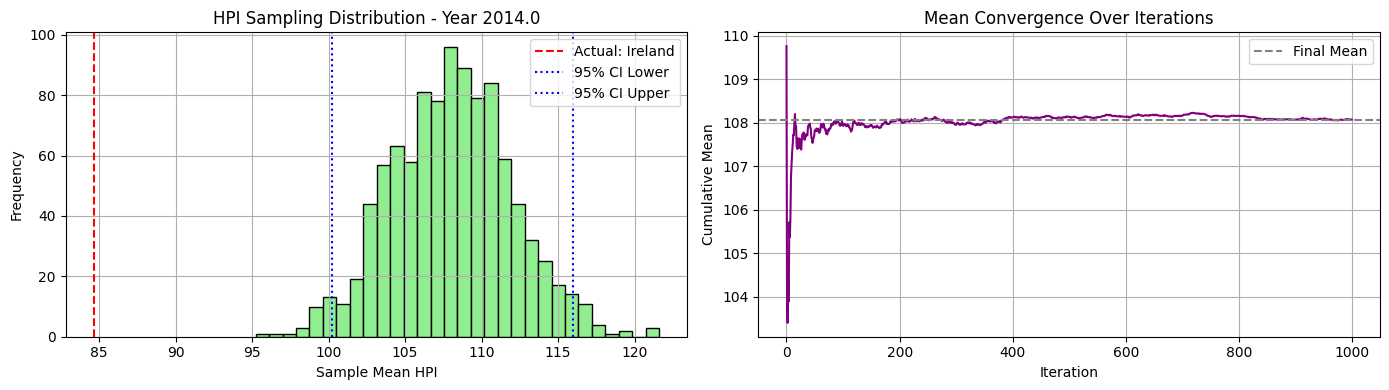


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54  83.68 156.46 106.5   83.68 140.12  84.67
 124.46 118.76 124.78 157.04 109.83  89.69 137.18 157.04  93.15  83.68
 107.92 103.    85.32  83.68 124.08]


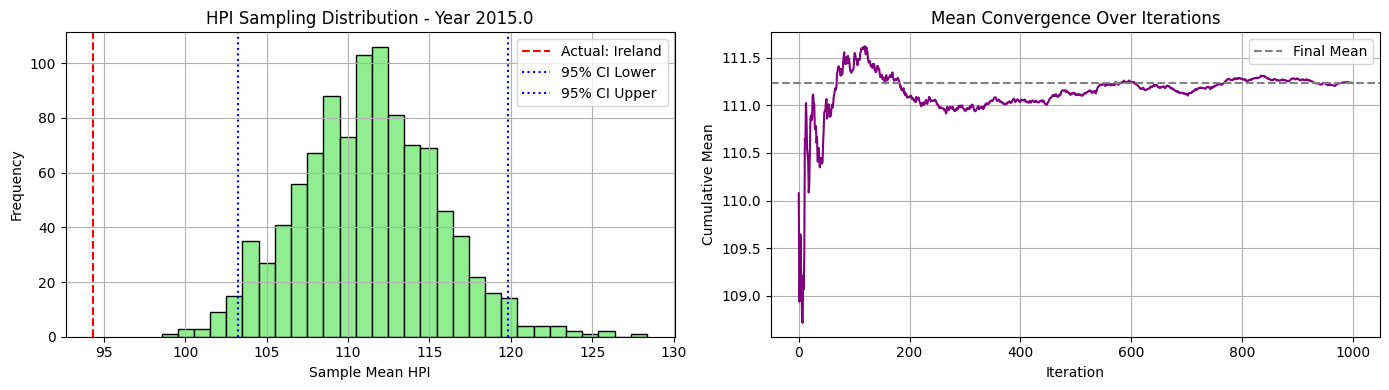


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33  84.88 163.86 107.86  84.88 150.56  84.88
 135.02 125.16 132.28 167.48 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   84.88 124.32]


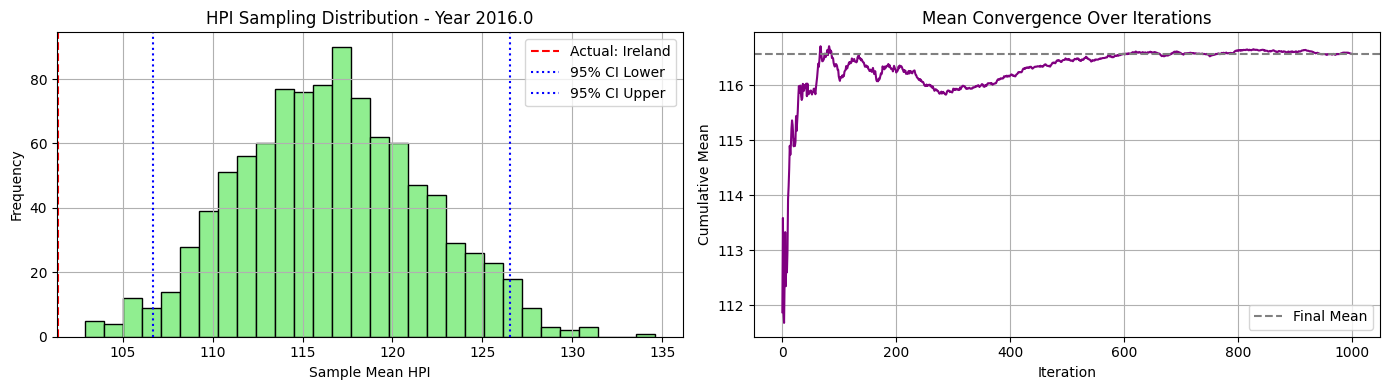


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84  83.98 172.91 109.02  83.98 156.44  83.98
 146.87 136.34 139.69 178.56 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  83.98 125.42]


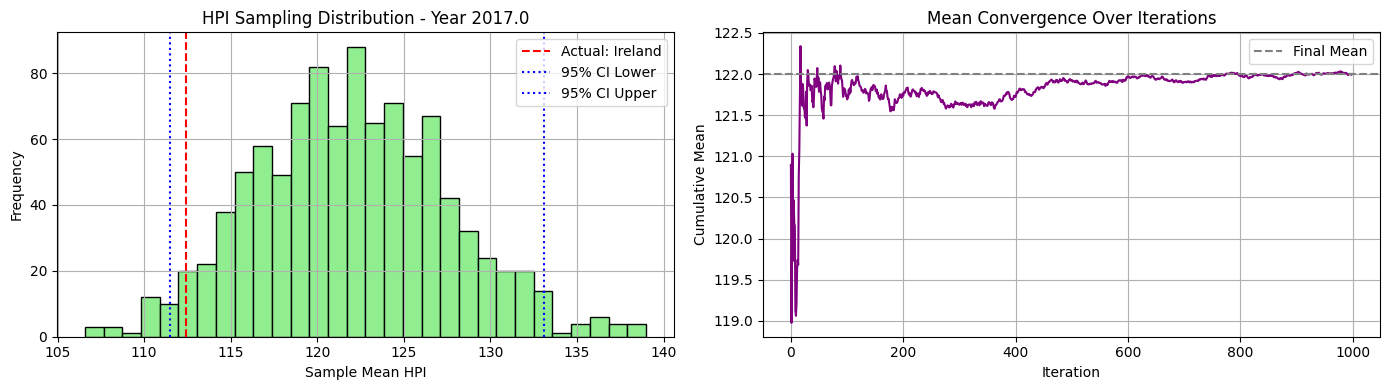


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59  88.13 183.13 110.06  88.13 155.14  88.13
 160.92 146.29 149.55 183.82 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   88.13 129.16]


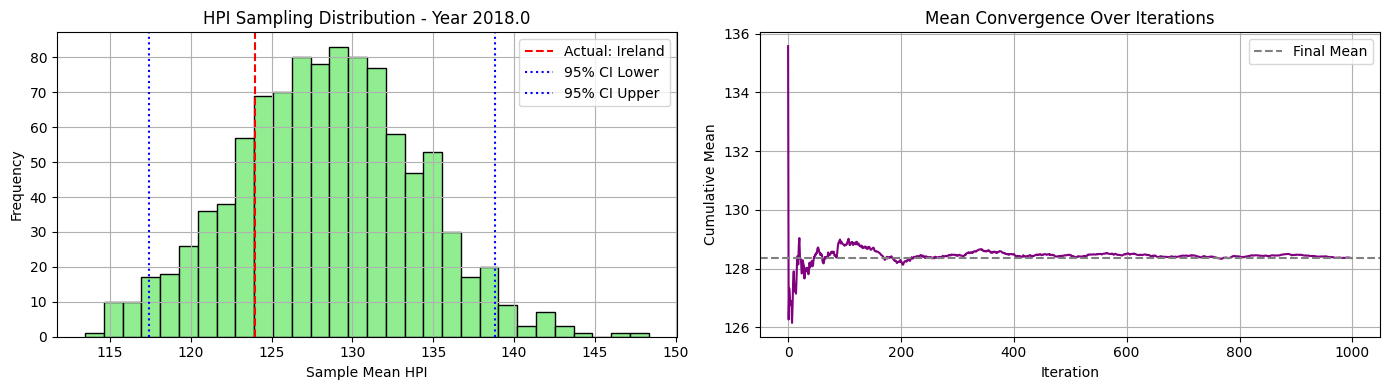


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64  92.69 195.98 110.52  92.69 158.06  92.69
 175.33 156.3  164.68 195.98 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  92.69 133.99]


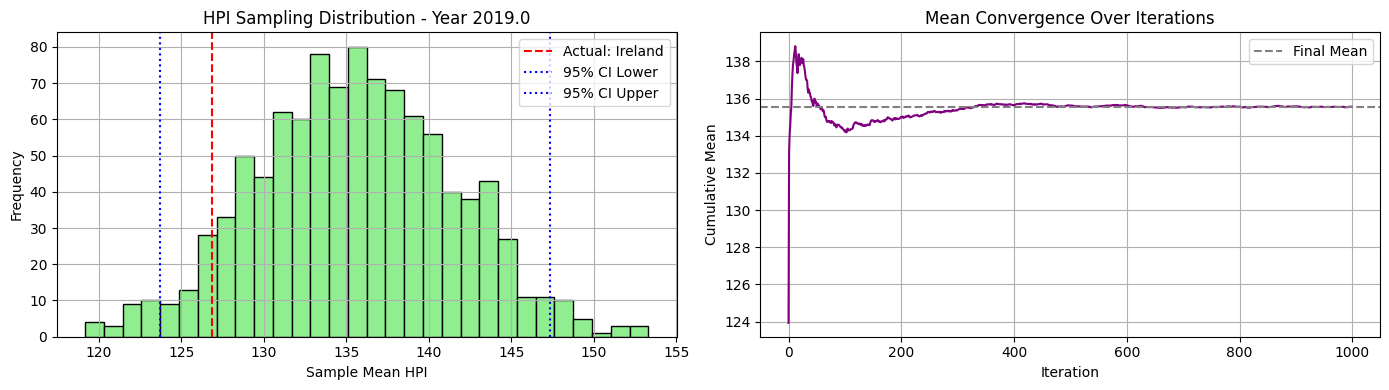


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06  94.76 203.12 112.49  94.76 162.9   94.76
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74  94.76 137.31]


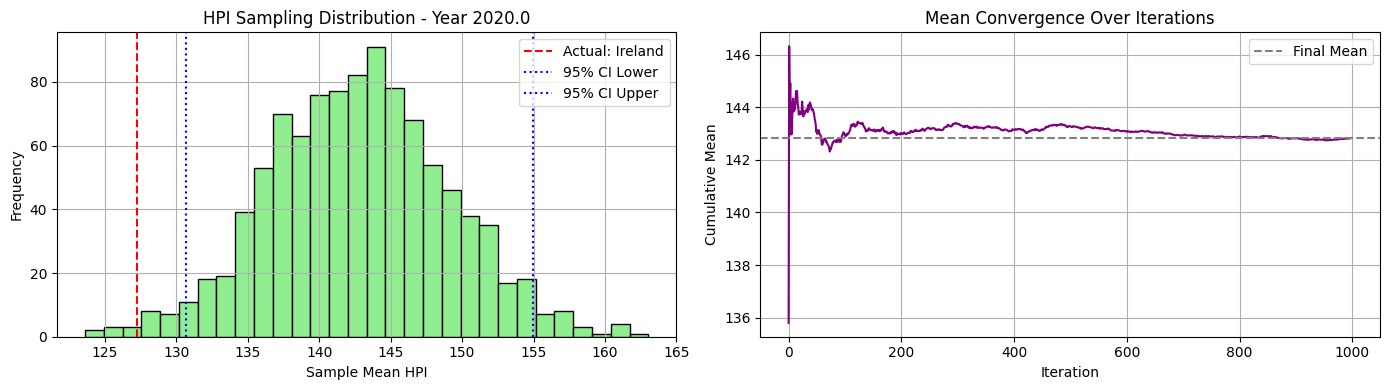


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64  98.24 222.1  117.62  98.24 176.65  98.24
 201.18 194.58 214.81 200.69 148.74 147.93 222.1  173.6  157.27 112.34
 125.04 158.94 129.1   98.24 145.16]


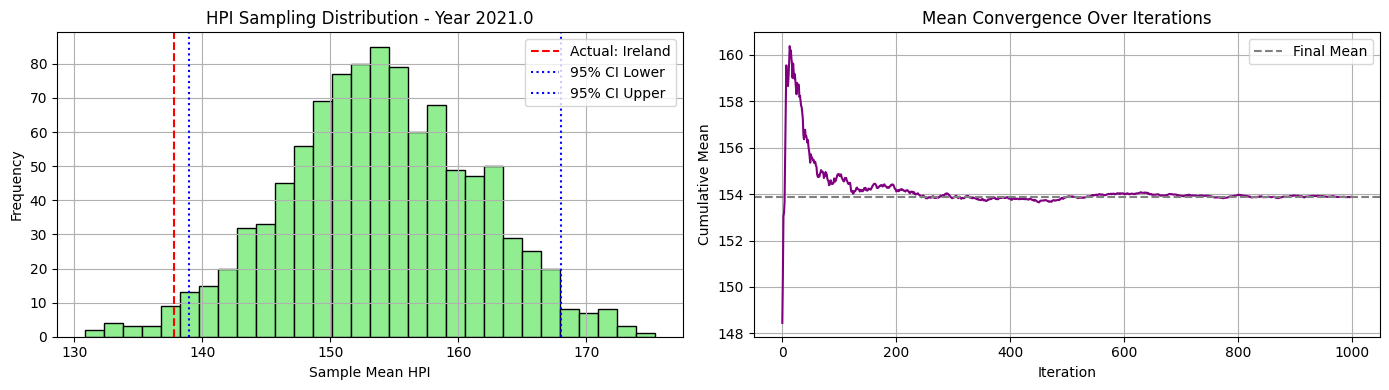


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 105.52 249.69 118.98 105.52 207.16 105.52
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 105.52 154.42]


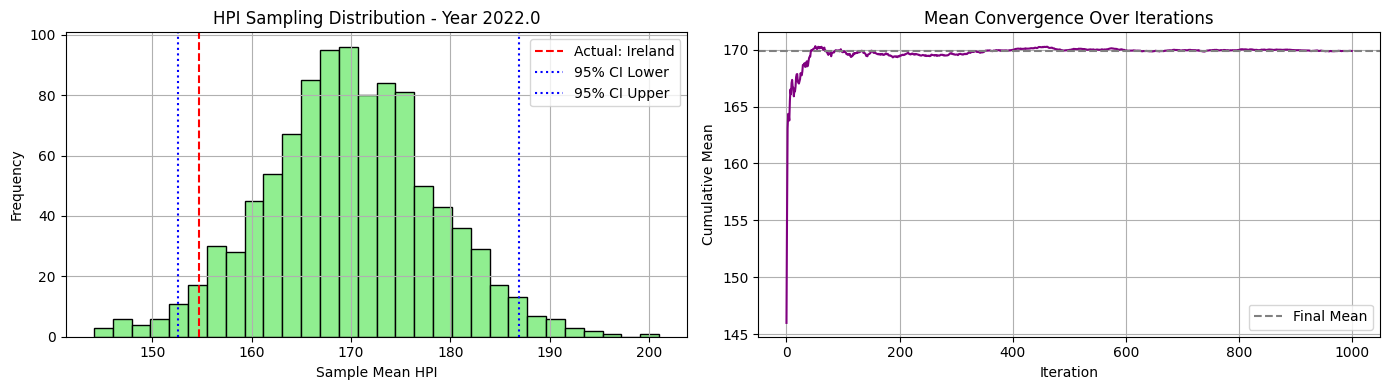


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 109.76 254.38 112.27 109.76 214.23 109.76
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 109.76 157.81]


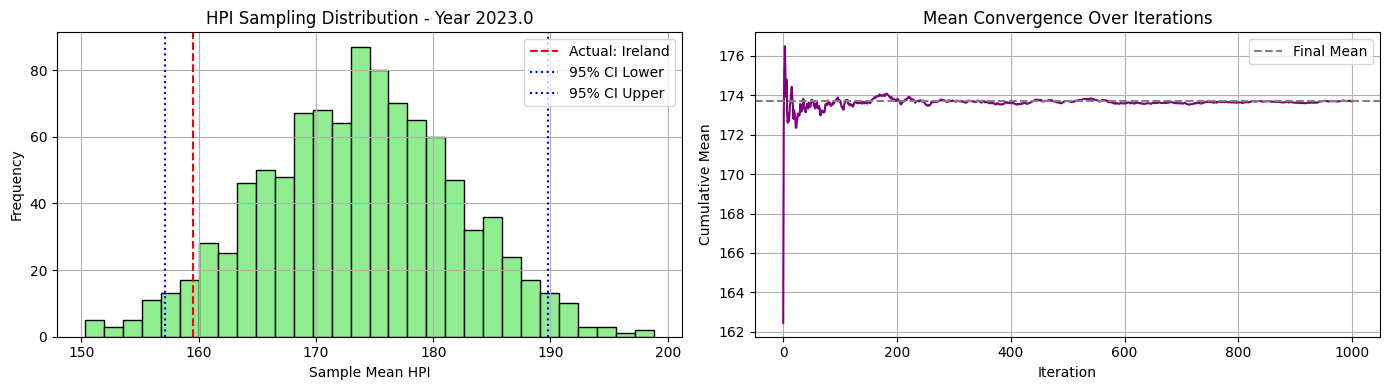


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  108.31 279.12 108.31 108.31 224.54 108.31
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


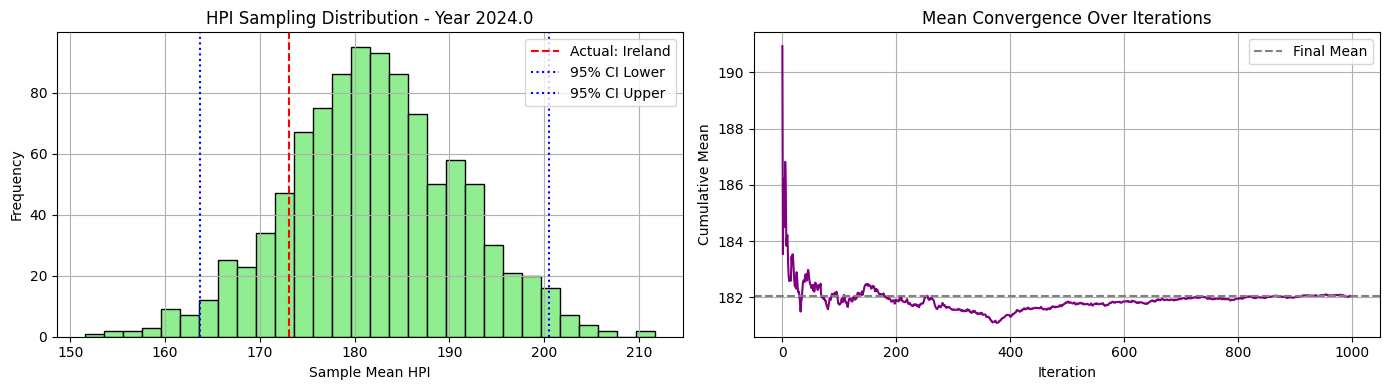

In [103]:
synthetic_c2_ni20_maxi500_h2_52_00, excluded_c2_ni20_maxi500_h2_52_00, actual_c2_ni20_maxi500_h2_52_00 = estimate_hpi_by_cluster_sampling(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=52)

🔍 Cluster 1 selected. Excluding country: Germany
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Czech-Republic', 'Denmark', 'France', 'Hungary', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Serbia', 'South-Africa', 'South-Korea', 'Sweden', 'Thailand', 'United-Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100.]


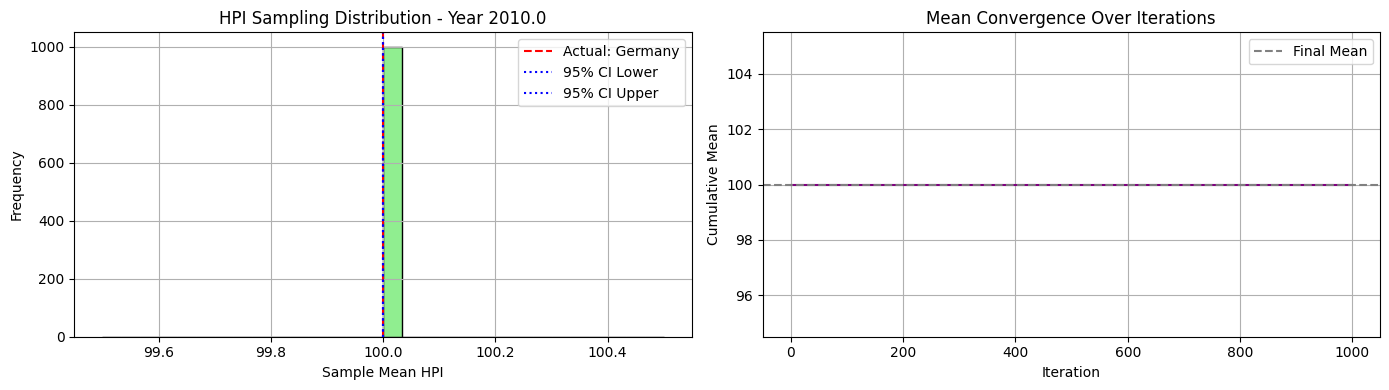


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 110.52 107.89 100.02  98.29 105.69  96.56 100.07
 105.8  108.01 105.57 100.08  97.62 103.59 105.23 102.58 104.26  98.54
  97.24]


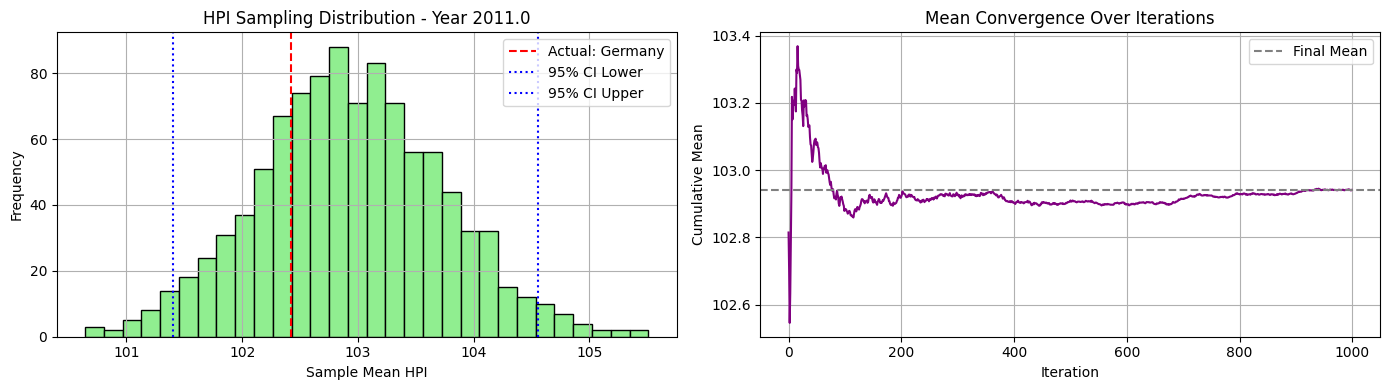


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62 124.02 118.79  98.56  95.67 105.11  92.98  99.19
 109.17 115.34 114.94  96.58  95.68 108.41 108.25 103.86 107.63  98.92
 101.82]


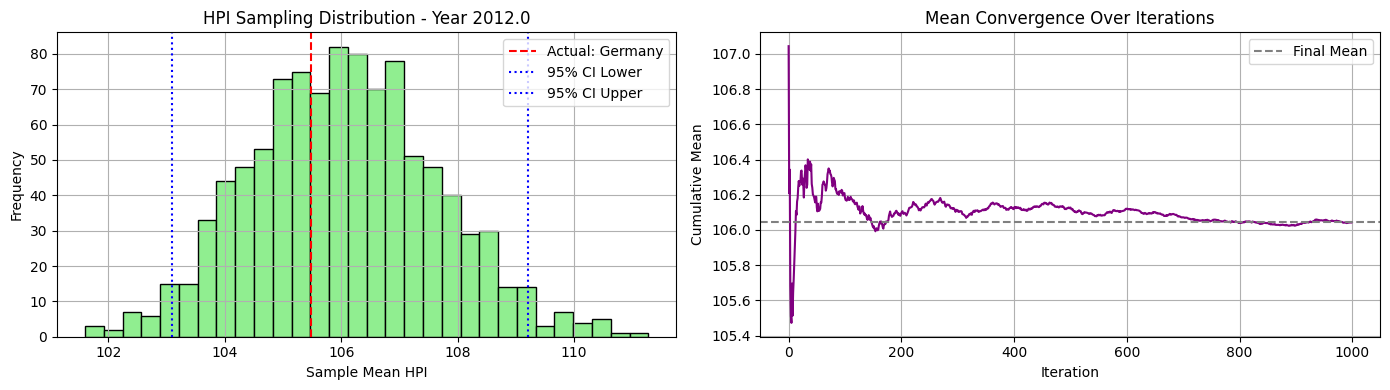


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76 136.52 130.06  98.58  99.37 103.13  90.58 100.81
 114.75 119.98 127.86  92.35  90.62 115.41 107.8  109.22 115.99 101.46
 111.83]


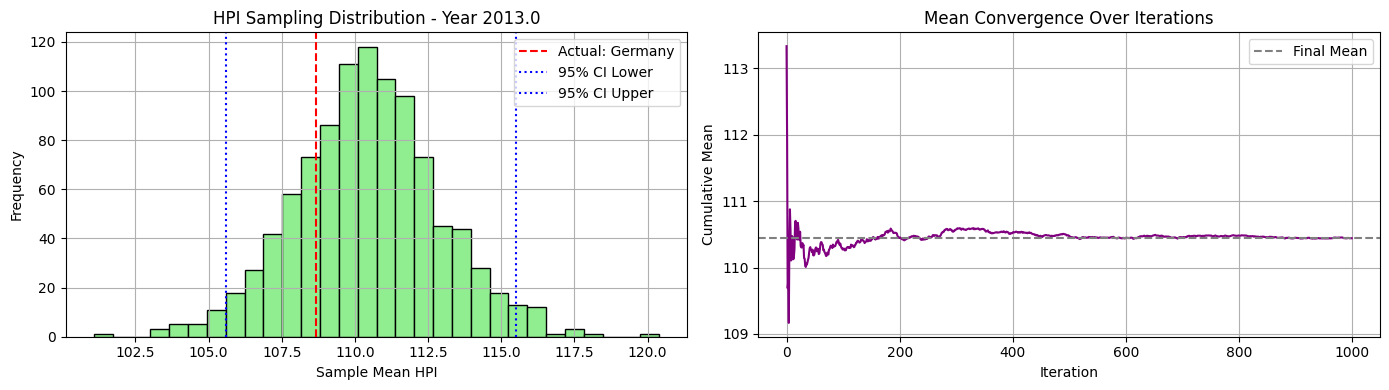


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 151.67 140.75 101.   103.12 101.58  94.37 102.38
 119.64 123.24 142.76  93.27  95.77 123.99 109.43 119.52 127.07 109.6
 118.88]


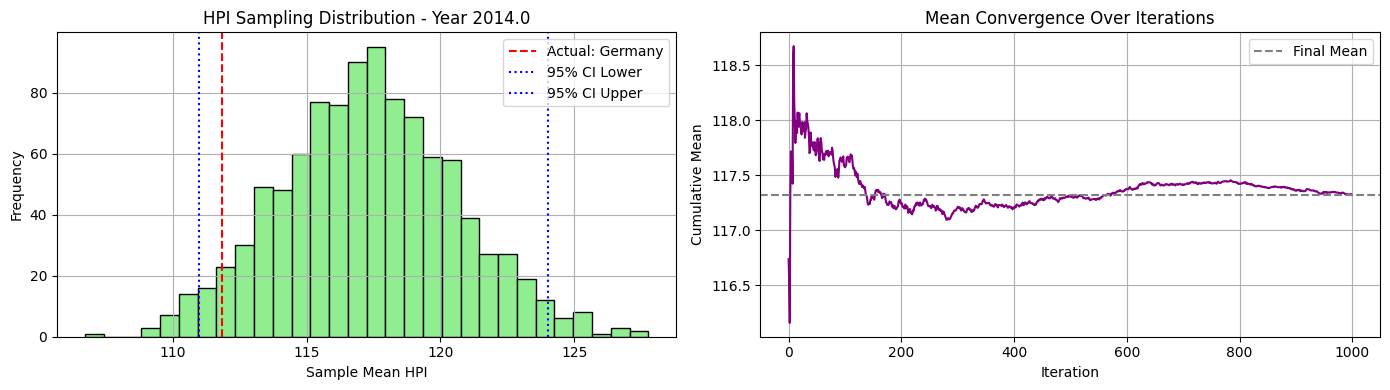


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 157.04 152.93 105.01 110.29 100.22 106.75 104.86
 129.39 130.76 157.04  94.69  99.5  131.8  113.08 135.2  136.   116.12
 125.18]


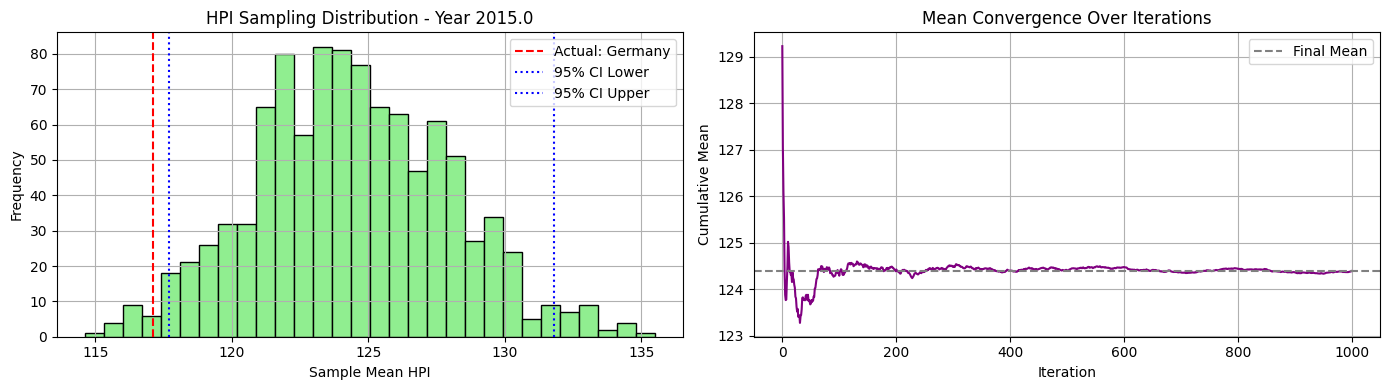


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 167.48 167.48 112.52 115.5  101.25 121.03 107.18
 138.82 139.95 167.48  96.44 110.62 138.22 116.09 146.34 142.4  124.27
 131.88]


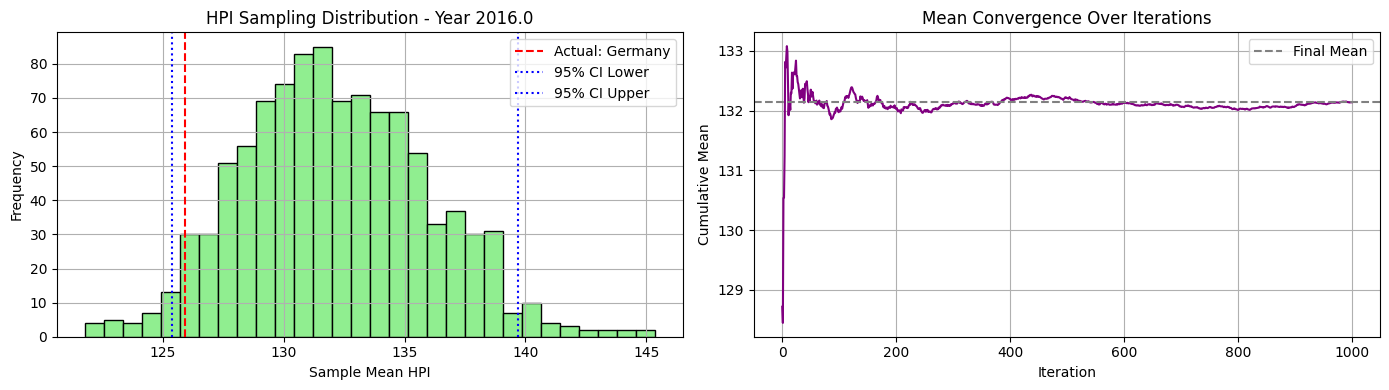


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  178.56 178.56 125.7  120.63 104.46 135.84 109.91
 149.69 146.91 178.56 100.16 115.3  143.94 117.6  156.06 146.48 129.93
 139.61]


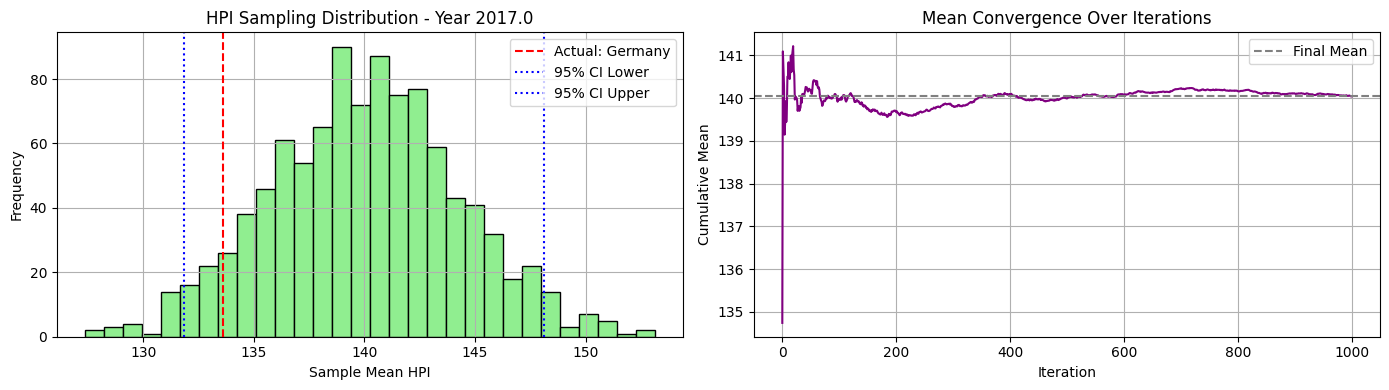


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 183.82 183.82 136.52 126.31 107.52 155.3  112.04
 162.97 149.04 183.82 106.75 123.06 148.96 120.22 154.6  153.9  134.04
 147.35]


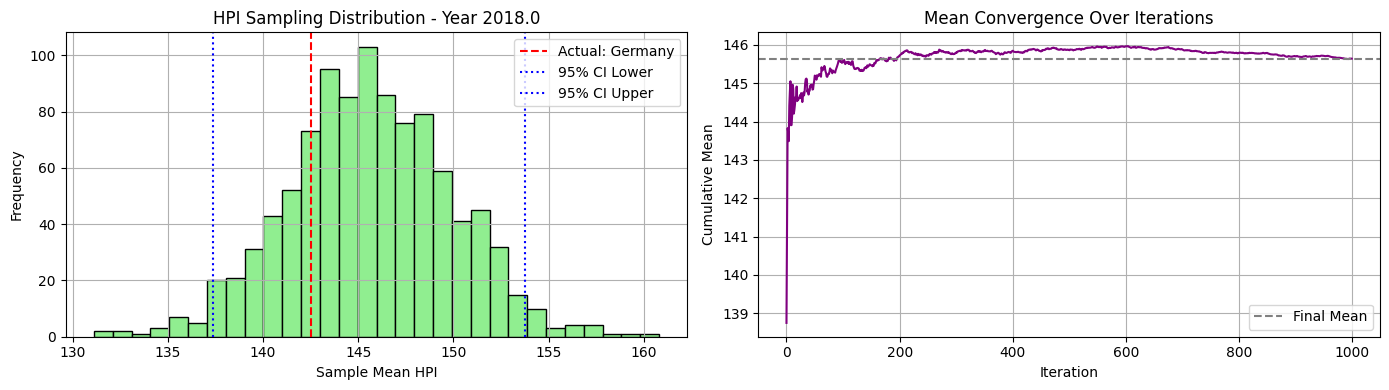


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  195.98 195.98 149.02 129.62 111.1  181.64 113.84
 176.92 152.73 195.26 116.01 135.77 152.69 121.93 158.44 155.1  135.37
 153.14]


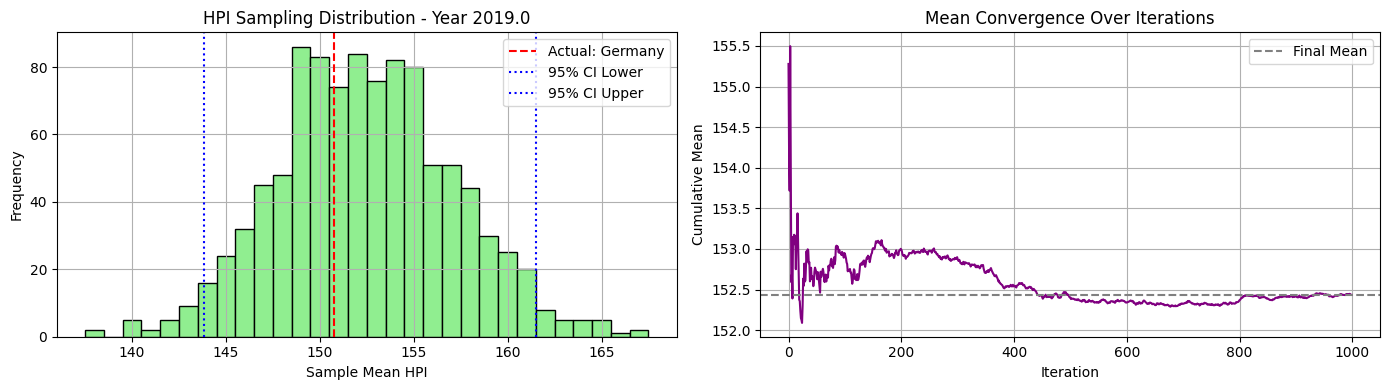


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 203.12 203.12 161.56 136.24 116.89 190.63 113.93
 187.18 159.24 203.12 128.18 149.28 156.31 126.56 165.09 160.6  139.24
 163.52]


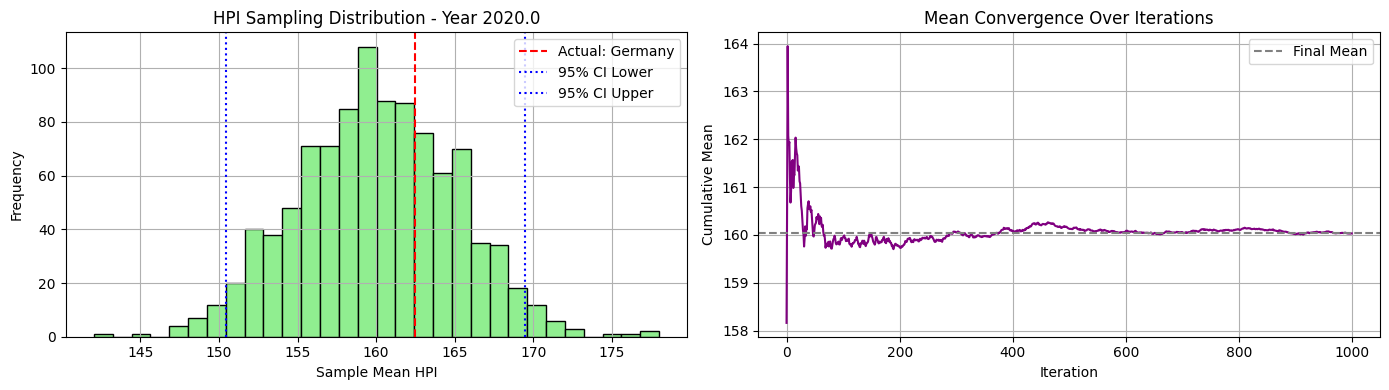


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 222.1  214.9  193.46 152.2  124.38 222.1  120.7
 201.94 175.91 211.74 139.92 166.04 166.82 143.73 181.79 164.23 150.58
 188.56]


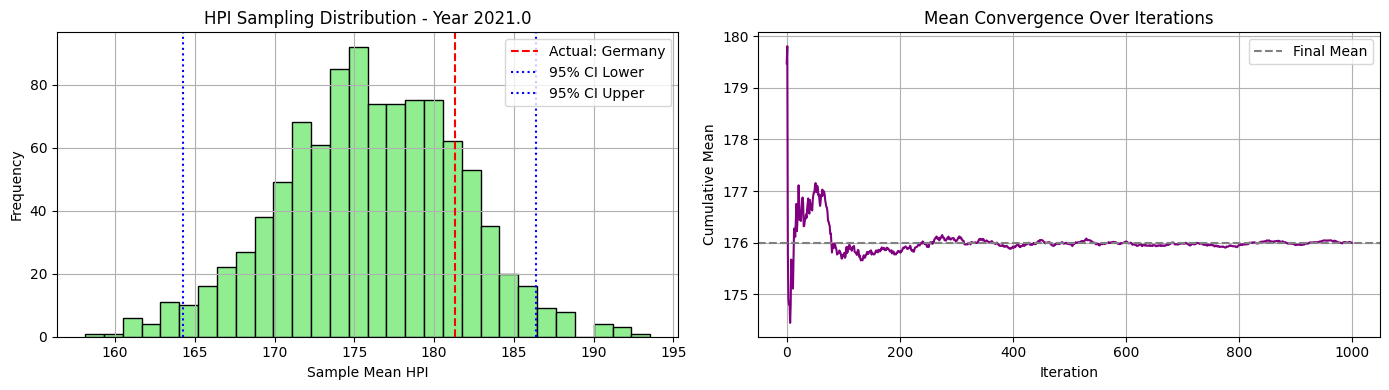


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 249.69 230.   226.15 151.49 132.1  249.69 130.84
 219.93 185.13 223.73 156.43 191.49 174.03 153.22 188.27 169.16 164.55
 213.  ]


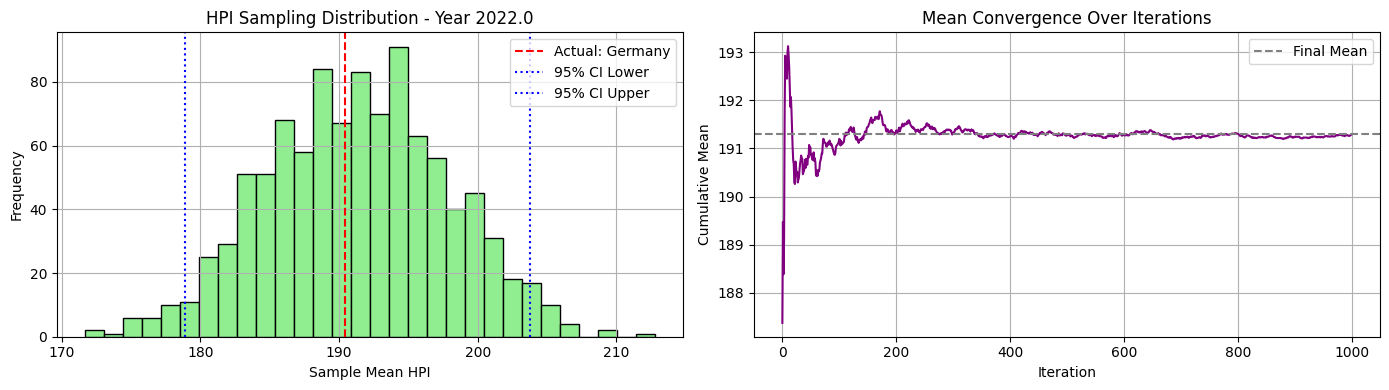


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 254.38 245.75 222.4  151.24 131.52 254.38 134.8
 243.89 184.12 248.04 170.23 209.99 176.62 143.99 178.36 174.79 165.
 221.72]


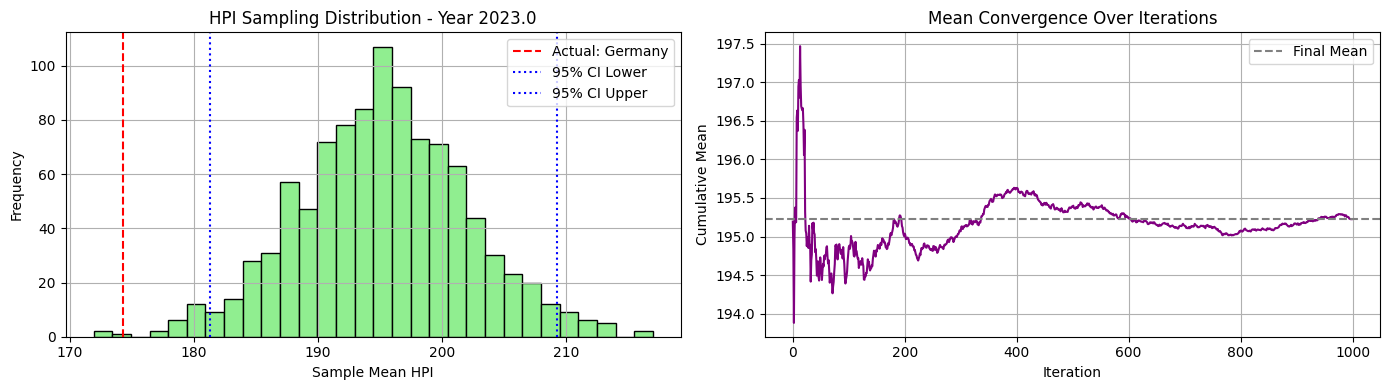


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 279.12 269.02 233.42 156.73 126.68 279.12 138.61
 266.38 189.05 256.03 195.72 220.7  178.1  142.46 178.49 178.06 166.38
 231.23]


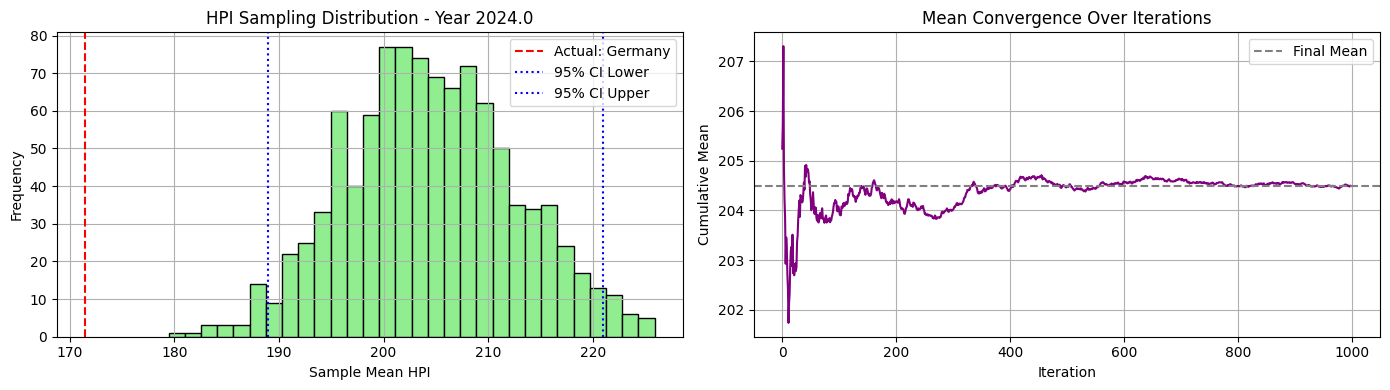

In [104]:
synthetic_c2_ni20_maxi500_h2_52_01, excluded_c2_ni20_maxi500_h2_52_01, actual_c2_ni20_maxi500_h2_52_01 = estimate_hpi_by_cluster_sampling(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=52)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [94]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [95]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [96]:
import re

def evaluate_all_seeds(synthetic_groups, actual_groups):
    """
    Evaluates multiple sets of synthetic vs. actual HPI dictionaries,
    and stores error metrics in a dictionary keyed by seed number.

    Parameters:
    - synthetic_groups: dict with keys like 'synthetic_42' and values as lists of synthetic dicts
    - actual_groups: dict with keys like 'actual_42' and values as lists of actual dicts

    Returns:
    - metrics_by_seed: dict with seed as key and {'mse': ..., 'mae': ...} as value
    """
    metrics_by_seed = {}

    for synthetic_key in synthetic_groups:
        # Extract seed number from the synthetic key
        match = re.search(r'_(\d+)$', synthetic_key)
        if not match:
            raise ValueError(f"Could not extract seed from key: {synthetic_key}")
        
        seed = int(match.group(1))
        actual_key = f'actual_{seed}'  # construct matching key for actual_groups

        if actual_key not in actual_groups:
            raise KeyError(f"Missing key in actual_groups: {actual_key}")

        synthetic_dicts = synthetic_groups[synthetic_key]
        actual_dicts = actual_groups[actual_key]

        mse, mae = compute_global_mse_mae(synthetic_dicts, actual_dicts)
        metrics_by_seed[seed] = {'mse': mse, 'mae': mae}

    return metrics_by_seed

In [97]:
def summarize_error_metrics(metrics_by_seed):
    """
    Computes the mean and median of MSE and MAE values across multiple seeds.

    Parameters:
    - metrics_by_seed: dictionary with seed as key and {'mse': ..., 'mae': ...} as value

    Returns:
    - summary: dictionary with keys 'mse_mean', 'mse_median', 'mae_mean', 'mae_median'
    """
    mse_values = [metrics['mse'] for metrics in metrics_by_seed.values()]
    mae_values = [metrics['mae'] for metrics in metrics_by_seed.values()]

    summary = {
        'mse_mean': np.mean(mse_values),
        'mse_median': np.median(mse_values),
        'mae_mean': np.mean(mae_values),
        'mae_median': np.median(mae_values)
    }

    return summary

In [105]:
a = [synthetic_c2_ni20_maxi500_h2_32_00, synthetic_c2_ni20_maxi500_h2_32_01]
b = [actual_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_01]

c = [synthetic_c2_ni20_maxi500_h2_43_00, synthetic_c2_ni20_maxi500_h2_43_01]
d = [actual_c2_ni20_maxi500_h2_43_00, actual_c2_ni20_maxi500_h2_43_01]

e = [synthetic_c2_ni20_maxi500_h2_52_00, synthetic_c2_ni20_maxi500_h2_52_01]
f = [actual_c2_ni20_maxi500_h2_52_00, actual_c2_ni20_maxi500_h2_52_01]

In [106]:
synth_c2_ni20_maxi500_h2 = {
    'synthetic_32': a,
    'synthetic_43': c,
    'synthetic_52': e
}

actual_c2_ni20_maxi500_h2 = {
    'actual_32': b,
    'actual_43': d,
    'actual_52': f
}

In [107]:
results_c2_ni20_maxi500_h2 = evaluate_all_seeds(synth_c2_ni20_maxi500_h2, actual_c2_ni20_maxi500_h2)

In [108]:
for seed, metrics in results_c2_ni20_maxi500_h2.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 393.5061, MAE: 15.5657
🔢 Seed 43 → MSE: 241.4480, MAE: 11.2054
🔢 Seed 52 → MSE: 164.2182, MAE: 9.7647


In [109]:
summary_c2_ni20_maxi500_h2 = summarize_error_metrics(results_c2_ni20_maxi500_h2)

In [110]:
print("📈 Error Summary Across Seeds:")
print(f"Mean MSE: {summary_c2_ni20_maxi500_h2['mse_mean']:.4f}")
print(f"Median MSE: {summary_c2_ni20_maxi500_h2['mse_median']:.4f}")
print(f"Mean MAE: {summary_c2_ni20_maxi500_h2['mae_mean']:.4f}")
print(f"Median MAE: {summary_c2_ni20_maxi500_h2['mae_median']:.4f}")

📈 Error Summary Across Seeds:
Mean MSE: 266.3907
Median MSE: 241.4480
Mean MAE: 12.1786
Median MAE: 11.2054


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [111]:
from datetime import datetime

In [112]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [113]:
pd.set_option('display.max_columns', None)

In [114]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
24,kmeans_plusplus_c2_ni20_maxi500_5_27deleted_wi...,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.408223,"RobustScaler, log transformation",Winsorization x5,True,False,"Winsorization, rounding",Winsorization x2,bootstrap,"[23, 32, 46]",3.0,657.423582,19.836296
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.359740,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,1518.505534,32.821709
28,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.393099,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352


In [115]:
new_entry_c2_ni20_maxi500_h2 = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_countries_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_c2_ni20_maxi500_h2,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'bootstrap',
    'mse_score': summary_c2_ni20_maxi500_h2['mse_mean'],
    'mae_score': summary_c2_ni20_maxi500_h2['mae_mean'],
    'sampling_seed': (32,43,52),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': h2,
    'used_pca_for_clustering': False,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 48
}

In [116]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry_c2_ni20_maxi500_h2])], ignore_index=True)

In [117]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.359740,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,1518.505534,32.821709
28,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.393099,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352
29,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.441491,"StandardScaler, log transformation",Winsorization,"[gdp, inflation_df, agr_land, livestock_prod]",False,"Winsorization, rounding",Winsorization,bootstrap,"(32, 43, 52)",3.0,266.390743,12.178599


In [118]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [119]:
def replace_country_count(df, column="countries_used_for_clustering", old_value=53, new_value=52):
    """
    Replaces all occurrences of a specific value in a given column with a new value.

    Parameters:
    - df (pd.DataFrame): The original DataFrame.
    - column (str): The name of the column where the replacement should occur (default is 'countries_used_for_clustering').
    - old_value (int or str): The value to be replaced (default is 53).
    - new_value (int or str): The value to replace with (default is 52).

    Returns:
    - pd.DataFrame: A new DataFrame with the specified replacements applied.
    """
    df = df.copy()
    df[column] = df[column].replace(old_value, new_value)
    return df

In [120]:
log_df = replace_country_count(log_df)

In [121]:
log_df.head()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,None,52,KMeans,3,random,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,None,52,continent based,4,None,NaN,NaN,42,None,None,0,NaN,None,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1652.241439,27.672956
2,baseline_kmeans_plusplus,2025-09-09 20:56,None,52,KMeans,3,k-means++,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507
3,kmeans_plusplus_without_outliers,2025-09-10 16:20,None,52,KMeans,3,k-means++,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation, Winsorization",Winsorization,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,566.926791,19.297330
4,kmeans_plusplus_elbow_silhouette_5,2025-09-10 19:38:00,None,52,KMeans,5,k-means++,10.0,100.0,42,False,False,0,0.230735,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1889.093940,29.773409


In [122]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.359740,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,1518.505534,32.821709
28,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.393099,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352
29,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.441491,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"(32, 43, 52)",3.0,266.390743,12.178599


In [124]:
def add_notebook_trace_column(df, column_name="source_notebook"):
    """
    Adds a new column to the DataFrame to trace the origin notebook (.ipynb) where each experiment was created.
    The column is initialized with None values and can be populated manually or programmatically later.

    Parameters:
    - df (pd.DataFrame): The original DataFrame.
    - column_name (str): The name of the new column to be added (default is 'source_notebook').

    Returns:
    - pd.DataFrame: A new DataFrame with the traceability column added.
    """
    df = df.copy()
    df[column_name] = None
    return df

In [125]:
log_df = add_notebook_trace_column(log_df)

In [129]:
log_df.loc[29, "source_notebook"] = "hypothesis_test_24.ipynb"

In [130]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755,None
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992,None
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.359740,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,1518.505534,32.821709,None
28,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.393099,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,None
29,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.441491,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"(32, 43, 52)",3.0,266.390743,12.178599,hypothesis_test_24.ipynb


In [131]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')